In [1]:
# Step 1
import numpy as np
import CoolProp.CoolProp as CP

In [2]:
# Step 2
# =====================================================================
# Full lunar day-night cycle: solar tower -> regolith TES -> sCO2 (simple + recuperated)
# Quasi-steady model following Prasad et al. (Table 2, Table 3, Appendix A)
# Day:   solar heat charges the TES; the cycle runs from the TES
# Night: the cycle runs from the TES only
# The turbine inlet always follows the TES: TIT = T_TES - dT_PHX
# =====================================================================

# --- Lunar day / night timing ---
t_lunar = 29.53 * 24       # h, synodic lunar day-night cycle
t_night = t_lunar / 2      # h, lunar night duration
t_day = t_lunar - t_night  # h, lunar daytime
dt = 1.0                   # h, time step
n_day = int(round(t_day / dt))
n_night = int(round(t_night / dt))
n_cycle = n_day + n_night
# snap durations to whole time steps so sunrise/sunset fall on a step
# (708.72 h -> 708 h with dt = 1 h: 354 h day + 354 h night)
t_day, t_night, t_lunar = n_day * dt, n_night * dt, n_cycle * dt

# --- Electrical demand (same day and night) ---
W_elec_target = 100.0      # kWe, habitat electrical demand (Table 2: 75-150 kWe)
eta_gen = 0.95             # generator efficiency (Table 2)

# --- Plant self-use (parasitic loads), on top of the habitat demand ---
# Assumed values (no lunar data): run as a sensitivity study
W_aux_fixed = 3.0          # kWe, controls, sensors, power electronics (always)
f_aux_heat = 0.01          # kWe per kW of Q_in, moving heat out of the regolith
f_aux_rad = 0.01           # kWe per kW of Q_rad, radiator loop pump
W_aux_day = 2.0            # kWe, heliostat drives (day only)
# The shaft power the cycle must deliver is solved each hour in Step 6:
#   W_net = (W_elec_target + parasitic loads) / eta_gen

# --- TES (regolith) ---
T_TES_max = 1000.0          # K, fully charged  
T_TES_min = 450.0          # K, lower limit   
rho_TES = 1500.0           # kg/m3, regolith bulk density (Table 3)
regolith_type = 'highlands'   # 'high_Ti_mare', 'low_Ti_mare', 'highlands'
TES_mass_margin = 1.20     # TES mass = margin x minimum mass for the night alone
# Heat loss from the TES through an insulating layer of loose regolith (Step 9):
#   Q_loss = k_reg(T_avg) * A_TES / L_ins * (T_TES - T_ground)
#   A_TES = surface of a cube holding the TES volume, k_reg from Table 3 (Step 3)
L_ins = 1.0                # m, thickness of loose-regolith insulation around the TES
T_ground = 250.0           # K, surrounding subsurface regolith (equator, below ~1 m)

# --- Solar tower / CSP ---
G_sun = 1361.0             # W/m2, solar irradiance at the Moon
eta_opt = 0.75             # optical efficiency (heliostats/concentrator)

# Receiver (replaces a fixed receiver efficiency): absorbs alpha_rec of the
# concentrated light and radiates eps_rec*sigma*T_rec^4 from its aperture.
alpha_rec = 0.95           # receiver absorptance
eps_rec = 0.90             # receiver emissivity (aperture radiation loss)
C_ratio = 200.0            # concentration ratio = collector area / receiver aperture area
dT_rec = 10.0              # K, receiver runs this much hotter than the TES (to charge it)
latitude_deg = 0.0         # site latitude (0 = equator)
collector_mode = 'fixed'   # 'fixed': flux x sin(sun elevation) (incidence angle)
                           # 'tracking': full flux whenever the sun is up
n_cycles_periodic = 4      # lunar cycles simulated to reach a repeating state

# --- sCO2 Brayton cycle (Table 2) ---
FLUID = 'CO2'
# The compressor inlet temperature is no longer fixed: each hour it is the
# coldest value the fixed radiator can reach (Step 6), never below T_comp_in.
T_comp_in = 320.0          # K, LOWEST compressor inlet temperature (radiator bypass below this)
T_comp_in_max = 380.0      # K, highest compressor inlet; if the radiator still cannot reject
                           #    the waste heat, the cycle runs at reduced power that hour
P_low = 8.0e6              # Pa, compressor inlet pressure, 80 bar (Table 2: 7.5-8.0 MPa)
P_high = 25.0e6            # Pa, compressor outlet pressure (Table 2: 20-25 MPa)
# Pressure drops, as a fraction of the pressure entering each component.
# The turbine inlet and outlet pressures follow from them (Steps 4 and 5):
#   turbine inlet  = P_high after the PHX (and recuperator cold side)
#   turbine outlet = what is needed so that, after the recuperator hot side
#                    and the cooler/radiator, P_low is left at the compressor
dp_PHX = 0.01              # PHX
dp_recup = 0.01            # each side of the recuperator
dp_cooler = 0.01           # cooler + radiator
eta_comp = 0.85            # compressor isentropic efficiency (NETL sCO2 studies: 0.85)
eta_turb = 0.90            # turbine isentropic efficiency (common sCO2 assumption: 0.90)
dT_PHX = 10.0              # K, primary HX approach: TIT = T_TES - dT_PHX
eta_cycle_min = 0.05       # cycle is shut down below this efficiency

# --- Cycle configurations (Section IV): both are calculated every run ---
cycles = ['simple', 'recuperated']
eps_recup = 0.95           # recuperator effectiveness (compact PCHE recuperators: ~0.95)

# Turbine inlet limit follows the TES automatically -- do not set by hand
TIT_max = T_TES_max - dT_PHX

# --- Habitat (heat balance each hour, Step 6) ---
# The habitat is held at T_hab. Its heat balance decides, hour by hour, whether
# it needs HEATING (taken from the cycle waste heat) or COOLING (its own thermal
# control system: radiator, plus a heat pump when the sky is too warm).
# Size from NASA Lunar Architecture Team: ~419 m3 pressurized volume for 4 crew.
T_hab = 295.0              # K, indoor temperature
n_crew = 4                 # crew
q_metab = 14e6 / 86400 / 1e3   # kW per person (14 MJ/person/day metabolic load)
V_hab = 419.0              # m3, pressurized volume (LAT-2 mean estimate, crew of 4)
D_hab = 6.0                # m, habitat diameter (cylinder with flat ends)
eps_MLI = 0.02             # MLI effective emittance of the habitat wall (typ. 0.015-0.03)
f_elec_inside = 1.0        # share of W_elec_target used inside the habitat (life support,
                           # experiments, cooling): it all ends up as heat inside
T_hab_rad = 283.0          # K, habitat radiator temperature (NASA surface habitat TCS)
T_hp_evap = 275.0          # K, heat-pump cold side (habitat coolant)
T_hp_cond = 360.0          # K, heat-pump hot side (radiator) when the sky is too warm
f_carnot_hp = 0.43         # heat-pump COP as a fraction of Carnot (NASA high-lift heat pump)
dT_hab_rad = 30.0          # K, use the heat pump when the sky is within this of T_hab_rad
_L_hab = V_hab / (np.pi * D_hab**2 / 4)
A_hab = np.pi * D_hab * _L_hab + 2 * np.pi * D_hab**2 / 4      # m2 wall area

# --- Plant radiator ---
# Radiator: the CO2 flows through the radiator panels, so the panel temperature
# falls along the panel from the cooler inlet to the compressor inlet (Step 6).
rad_area_margin = 1.10     # installed radiator = margin x largest night need (fixed hardware)
emissivity = 0.85          # radiator emissivity (0.6-0.9)
sigma = 5.670374419e-8     # W/m2-K4

# --- Radiator environment (varies with the sun angle, see Step 8) ---
T_surf_night = 100.0       # K, lunar surface at night
T_surf_noon = 392.0        # K, lunar surface at noon (equator)
T_space = 3.0              # K, deep space
F_rad_surf = 0.5           # radiator view factor to the lunar surface (vertical panel)
shield = True              # True: radiator shaded from the surface (sees space only)
_F = 0.0 if shield else F_rad_surf
T_sink_night = (_F * T_surf_night**4 + (1 - _F) * T_space**4) ** 0.25   # K, night sink

# --- Input checks: stop with a clear message if inputs are inconsistent ---
T_crit, P_crit = 304.13, 7.3773e6     # CO2 critical point
# timing
assert dt > 0, "dt must be > 0"
assert 0 < t_night < t_lunar, "t_night must be shorter than the lunar cycle"
assert n_cycles_periodic >= 1, "n_cycles_periodic must be >= 1"
# demand and parasitic loads
assert W_elec_target > 0, "W_elec_target must be > 0"
assert W_aux_fixed >= 0 and W_aux_day >= 0, "Fixed parasitic loads must be >= 0"
assert 0 <= f_aux_heat < 0.2 and 0 <= f_aux_rad < 0.2, "Parasitic fractions must be in [0, 0.2)"
# TES
assert T_TES_max > T_TES_min, "T_TES_max must be greater than T_TES_min"
assert T_TES_min >= 350, "Regolith cp correlation (Table 3, T > 350 K) needs T_TES_min >= 350 K"
assert T_TES_max <= 1100, "Above ~1100 K regolith starts to sinter and CoolProp CO2 data end"
assert rho_TES > 0, "rho_TES must be > 0"
assert TES_mass_margin > 1.0, "TES_mass_margin must be > 1 so the TES survives dawn and dusk"
assert L_ins > 0, "L_ins must be > 0"
assert 0 < T_ground < T_TES_min, "T_ground must be below T_TES_min"
# solar / receiver
assert 0 < eta_opt <= 1, "eta_opt must be in (0, 1]"
assert 0 < alpha_rec <= 1 and 0 < eps_rec <= 1, "Receiver absorptance/emissivity must be in (0, 1]"
assert C_ratio > 1, "C_ratio must be > 1"
assert dT_rec >= 0, "dT_rec must be >= 0"
assert -90 < latitude_deg < 90, "latitude_deg must be between -90 and 90 (poles excluded)"
assert collector_mode in ('fixed', 'tracking'), "collector_mode must be 'fixed' or 'tracking'"
# cycle
assert T_comp_in > T_crit, f"T_comp_in must be above CO2 critical temperature ({T_crit} K)"
assert P_low > P_crit, f"P_low must be above CO2 critical pressure ({P_crit/1e6:.2f} MPa)"
assert P_high > P_low, "P_high must be greater than P_low"
assert 0 < eta_comp <= 1 and 0 < eta_turb <= 1 and 0 < eta_gen <= 1, "Efficiencies must be in (0, 1]"
assert dT_PHX >= 0, "dT_PHX must be >= 0"
assert TIT_max > T_comp_in + 30, "TES too cold: turbine inlet would be below the compressor range"
assert 0 <= eta_cycle_min < 1, "eta_cycle_min must be in [0, 1)"
assert 0 <= eps_recup < 1, "eps_recup must be in [0, 1)"
# waste heat / radiator / environment
assert 0 < eps_MLI < 1 and 0 <= f_elec_inside <= 1, "eps_MLI and f_elec_inside must be in (0, 1)"
assert T_hp_cond > T_hab > T_hp_evap and 0 < f_carnot_hp <= 1, "Check the heat-pump inputs"
assert T_comp_in > T_hab, "Compressor inlet must be warmer than the habitat to heat it"
assert 0 < emissivity <= 1, "emissivity must be in (0, 1]"
assert T_comp_in_max > T_comp_in, "T_comp_in_max must be above T_comp_in"
assert T_comp_in > T_sink_night, "Compressor inlet must be hotter than the night sink"
assert 0 <= dp_PHX < 0.1 and 0 <= dp_recup < 0.1 and 0 <= dp_cooler < 0.1, "Pressure drops must be in [0, 0.1)"
assert rad_area_margin >= 1.0, "rad_area_margin must be >= 1"
assert T_surf_noon > T_surf_night > T_space, "Need T_surf_noon > T_surf_night > T_space"
assert 0 <= F_rad_surf <= 1, "F_rad_surf must be between 0 and 1"

# --- Soft warnings: allowed, but outside the paper's Table 2 ranges ---
for _name, _v, _lo, _hi, _u in [("T_comp_in", T_comp_in, 305, 320, "K"),
                                ("P_low", P_low / 1e6, 7.5, 8.0, "MPa"),
                                ("P_high", P_high / 1e6, 20, 25, "MPa")]:
    if not (_lo <= _v <= _hi):
        print(f"Note: {_name} = {_v:g} {_u} is outside Table 2 ({_lo}-{_hi} {_u})")

print(f"Inputs OK: cycles {cycles}, TES {T_TES_max:.0f} -> {T_TES_min:.0f} K, TIT max {TIT_max:.0f} K, "
      f"PR {P_high/P_low:.2f}, {W_elec_target:.0f} kWe + parasitic ({W_aux_fixed:.0f} kWe fixed, "
      f"{W_aux_day:.0f} kWe day), compressor inlet {T_comp_in:.0f}-{T_comp_in_max:.0f} K at "
      f"{P_low/1e6:.1f} MPa, day {t_day:.0f} h / night {t_night:.0f} h")

Inputs OK: cycles ['simple', 'recuperated'], TES 1000 -> 450 K, TIT max 990 K, PR 3.12, 100 kWe + parasitic (3 kWe fixed, 2 kWe day), compressor inlet 320-380 K at 8.0 MPa, day 354 h / night 354 h


In [3]:
# Step 3
# ---------------------------------------------------------------------
# Regolith specific heat (Table 3, Schreiner et al. 2016)
# For T > 350 K: cp = Cf + Cg*T + Ch/T^2   [J/kg-K]
# (The 100-350 K polynomial in Table 3 gives J/g-K, not J/kg-K;
#  it is not needed here because the TES stays at or above 350 K.)
# ---------------------------------------------------------------------
REGOLITH_CP = {
    'high_Ti_mare': (8.820e2, 3.083e-1, -2.278e7),
    'low_Ti_mare':  (9.093e2, 2.870e-1, -2.469e7),
    'highlands':    (9.530e2, 2.524e-1, -2.645e7),
}
Cf, Cg, Ch = REGOLITH_CP[regolith_type]

def cp_regolith(T):
    return Cf + Cg * T - (-Ch) / T**2      # J/kg-K  (Ch is negative)

def e_regolith(T):
    """Specific sensible energy relative to T_TES_min, J/kg (integral of cp dT)."""
    F = lambda T: Cf * T + 0.5 * Cg * T**2 - Ch / T
    return F(T) - F(T_TES_min)

# Lookup table for inverting energy -> temperature
T_grid_TES = np.linspace(T_TES_min - 50, T_TES_max + 1, 4000)
e_grid_TES = e_regolith(T_grid_TES)

def T_from_e(e):
    return np.interp(e, e_grid_TES, T_grid_TES)

def k_regolith(T):
    """Thermal conductivity of granular regolith, W/m-K (Table 3)."""
    return 0.001561 + 5.426e-11 * np.asarray(T)**3

def TES_heat_loss(T_TES, m_TES):
    """Heat lost through the insulation, kW. TES = cube of volume m/rho."""
    A = 6 * (m_TES / rho_TES) ** (2 / 3)                     # m2
    k = k_regolith(0.5 * (T_TES + T_ground))                 # insulation at its mean temperature
    return k * A / L_ins * (T_TES - T_ground) / 1e3

In [4]:
# Step 4
# ---------------------------------------------------------------------
# Simple sCO2 Brayton cycle (Appendix Table A, Eq. 1-10) with pressure drops
# States: 1 compressor in, 2 compressor out / PHX in,
#         3 PHX out / turbine in, 4 turbine out / cooler in
# Pressures: P1 = P_low, P2 = P_high, P3 = P2*(1 - dp_PHX),
#            P4 = P1/(1 - dp_cooler)  (the turbine expands only to the pressure
#            that leaves P_low after the cooler/radiator)
# T1 = compressor inlet temperature, set each hour by the radiator (Step 6).
# Results are pre-computed on a (T1, TIT) grid and stored in CYC[cycle];
# cycle_row(TIT, ct) gives all T1 values at one TIT, cycle_at(TIT, ct, T1) one point.
# ---------------------------------------------------------------------
P_simple = dict(P1=P_low, P2=P_high, P3=P_high * (1 - dp_PHX), P4=P_low / (1 - dp_cooler))

def simple_cycle(TIT, T1=None):
    T1 = T_comp_in if T1 is None else T1
    P = P_simple
    h1 = CP.PropsSI('H', 'T', T1, 'P', P['P1'], FLUID)
    s1 = CP.PropsSI('S', 'T', T1, 'P', P['P1'], FLUID)
    h2s = CP.PropsSI('H', 'S', s1, 'P', P['P2'], FLUID)
    h2 = h1 + (h2s - h1) / eta_comp                      # Eq. 8
    h3 = CP.PropsSI('H', 'T', TIT, 'P', P['P3'], FLUID)
    s3 = CP.PropsSI('S', 'T', TIT, 'P', P['P3'], FLUID)
    h4s = CP.PropsSI('H', 'S', s3, 'P', P['P4'], FLUID)
    h4 = h3 - eta_turb * (h3 - h4s)                      # Eq. 10

    w_c = h2 - h1                 # Eq. 1 (per kg)
    q_in = h3 - h2                # Eq. 2
    w_t = h3 - h4                 # Eq. 3
    q_out = h4 - h1               # Eq. 4
    w_net = w_t - w_c             # Eq. 5
    eta = w_net / q_in            # Eq. 6
    T2 = CP.PropsSI('T', 'H', h2, 'P', P['P2'], FLUID)
    T4 = CP.PropsSI('T', 'H', h4, 'P', P['P4'], FLUID)
    return dict(eta=eta, w_net=w_net, w_c=w_c, w_t=w_t, q_in=q_in, q_out=q_out,
                q_rec=0.0, T1=T1, T2=T2, T4=T4, T_cool_in=T4, h_cool_in=h4,
                h1=h1, h2=h2, h3=h3, h4=h4,
                P=[P['P1'], P['P2'], P['P3'], P['P4']])

# --- Grids: compressor inlet T1 x turbine inlet TIT ---
T1_grid = np.arange(T_comp_in, T_comp_in_max + 0.1, 2.5)
TIT_grid = np.unique(np.append(np.arange(T_comp_in + 30, TIT_max, 5.0), TIT_max))
KEYS = ['eta', 'w_net', 'w_c', 'w_t', 'q_in', 'q_out', 'q_rec', 'h1', 'h_cool_in', 'T_cool_in']

def build_cycle_table(cycle_fn):
    """Pre-compute a cycle on the (T1, TIT) grid. The TES cutoff uses the coldest T1."""
    G = {k: np.full((len(T1_grid), len(TIT_grid)), np.nan) for k in KEYS}
    for i, T1 in enumerate(T1_grid):
        for j, TIT in enumerate(TIT_grid):
            try:
                r = cycle_fn(TIT, T1)
            except ValueError:
                continue
            for k in KEYS:
                G[k][i, j] = r[k]
    with np.errstate(invalid='ignore'):
        ok = (G['w_net'][0] > 0) & (G['q_in'][0] > 0) & (G['eta'][0] >= eta_cycle_min)
    # lowest TIT at which the cycle still works (scan down from TIT_max, stop at first failure)
    first_fail_from_top = np.argmax(~ok[::-1])
    TIT_cut = TIT_grid[len(TIT_grid) - first_fail_from_top] if not ok.all() else TIT_grid[0]
    return dict(G=G, TIT_cutoff=TIT_cut, T_TES_cutoff=max(T_TES_min, TIT_cut + dT_PHX))

def cycle_row(TIT, ct):
    """All cycle results versus T1 (arrays over T1_grid) at one TIT, plus a 'works' mask."""
    j = int(np.clip(np.searchsorted(TIT_grid, TIT) - 1, 0, len(TIT_grid) - 2))
    w = (TIT - TIT_grid[j]) / (TIT_grid[j + 1] - TIT_grid[j])
    G = CYC[ct]['G']
    r = {k: G[k][:, j] * (1 - w) + G[k][:, j + 1] * w for k in KEYS}
    with np.errstate(invalid='ignore'):
        r['ok'] = (r['w_net'] > 0) & (r['q_in'] > 0) & (r['eta'] >= eta_cycle_min)
    return r

def cycle_at(TIT, ct='simple', T1=None):
    """Cycle results at one (TIT, T1); T1 defaults to the coldest compressor inlet."""
    T1 = T_comp_in if T1 is None else T1
    r = cycle_row(TIT, ct)
    return {k: float(np.interp(T1, T1_grid, r[k])) for k in KEYS}

print(f"Building simple-cycle map ({len(T1_grid)} x {len(TIT_grid)} points)...")
CYC = {'simple': build_cycle_table(simple_cycle)}
print(f"simple cycle: turbine {P_simple['P3']/1e6:.2f} -> {P_simple['P4']/1e6:.2f} MPa, "
      f"eta at TIT {TIT_max:.0f} K / T1 {T_comp_in:.0f} K = {cycle_at(TIT_max, 'simple')['eta']*100:.2f} %, "
      f"usable TES down to {CYC['simple']['T_TES_cutoff']:.0f} K")

Building simple-cycle map (25 x 129 points)...
simple cycle: turbine 24.75 -> 8.08 MPa, eta at TIT 990 K / T1 320 K = 15.83 %, usable TES down to 475 K


In [5]:
# Step 5
# ---------------------------------------------------------------------
# Recuperated sCO2 Brayton cycle (Appendix Table A, Eq. 11-20)
# States: 1 compressor in        2 compressor out / recuperator cold in
#         3 recuperator cold out / PHX in      4 PHX out / turbine in (TIT)
#         5 turbine out / recuperator hot in   6 recuperator hot out / cooler in
# Pressures: P1 = P_low, P2 = P_high, P3 = P2(1-dp_recup), P4 = P3(1-dp_PHX),
#            P6 = P1/(1-dp_cooler), P5 = P6/(1-dp_recup)
# Recuperator duty = eps_recup x the largest possible duty (limited by the
# stream that can change least), so neither stream crosses the other's inlet T.
# ---------------------------------------------------------------------
P_recup = dict(P1=P_low, P2=P_high, P3=P_high * (1 - dp_recup))
P_recup['P4'] = P_recup['P3'] * (1 - dp_PHX)                 # turbine inlet
P_recup['P6'] = P_low / (1 - dp_cooler)                      # recuperator hot out / cooler in
P_recup['P5'] = P_recup['P6'] / (1 - dp_recup)               # turbine outlet

def recuperated_cycle(TIT, T1=None):
    T1 = T_comp_in if T1 is None else T1
    P = P_recup
    h1 = CP.PropsSI('H', 'T', T1, 'P', P['P1'], FLUID)
    s1 = CP.PropsSI('S', 'T', T1, 'P', P['P1'], FLUID)
    h2s = CP.PropsSI('H', 'S', s1, 'P', P['P2'], FLUID)
    h2 = h1 + (h2s - h1) / eta_comp                      # Eq. 8
    T2 = CP.PropsSI('T', 'H', h2, 'P', P['P2'], FLUID)
    h4 = CP.PropsSI('H', 'T', TIT, 'P', P['P4'], FLUID)
    s4 = CP.PropsSI('S', 'T', TIT, 'P', P['P4'], FLUID)
    h5s = CP.PropsSI('H', 'S', s4, 'P', P['P5'], FLUID)
    h5 = h4 - eta_turb * (h4 - h5s)                      # Eq. 10
    T5 = CP.PropsSI('T', 'H', h5, 'P', P['P5'], FLUID)

    # Recuperator (Eq. 11-14): duty = eps_recup x the largest possible duty
    dh_hot_max = h5 - CP.PropsSI('H', 'T', T2, 'P', P['P6'], FLUID)   # hot side cooled to T2
    dh_cold_max = CP.PropsSI('H', 'T', T5, 'P', P['P3'], FLUID) - h2  # cold side heated to T5
    q_rec = eps_recup * max(min(dh_hot_max, dh_cold_max), 0.0)        # Eq. 13: Q_cold = Q_hot
    h3 = h2 + q_rec                                      # Eq. 11
    h6 = h5 - q_rec                                      # Eq. 12
    T3 = CP.PropsSI('T', 'H', h3, 'P', P['P3'], FLUID)
    T6 = CP.PropsSI('T', 'H', h6, 'P', P['P6'], FLUID)

    w_c = h2 - h1                 # Eq. 17 (per kg)
    q_in = h4 - h3                # Eq. 15: heat from TES after recuperation
    w_t = h4 - h5                 # Eq. 16
    q_out = h6 - h1               # Eq. 20: heat rejected after recuperation
    w_net = w_t - w_c             # Eq. 18
    eta = w_net / q_in            # Eq. 19
    return dict(eta=eta, w_net=w_net, w_c=w_c, w_t=w_t, q_in=q_in, q_out=q_out,
                q_rec=q_rec, T1=T1, T2=T2, T3=T3, T5=T5, T6=T6, T_cool_in=T6, h_cool_in=h6,
                h1=h1, h2=h2, h3=h3, h4=h4, h5=h5, h6=h6,
                P=[P['P1'], P['P2'], P['P3'], P['P4'], P['P5'], P['P6']])

def cycle_state_table(TIT, ct, T1=None):
    """Cycle results and (name, T, P) of every state, for the report."""
    if ct == 'recuperated':
        r = recuperated_cycle(TIT, T1)
        names = ['1  Compressor inlet', '2  Compressor outlet', '3  Recuperator cold out',
                 '4  Turbine inlet', '5  Turbine outlet', '6  Cooler inlet']
        temps = [r['T1'], r['T2'], r['T3'], TIT, r['T5'], r['T6']]
    else:
        r = simple_cycle(TIT, T1)
        names = ['1  Compressor inlet', '2  Compressor outlet', '3  Turbine inlet', '4  Turbine outlet']
        temps = [r['T1'], r['T2'], TIT, r['T4']]
    return r, list(zip(names, temps, r['P']))

print(f"Building recuperated-cycle map ({len(T1_grid)} x {len(TIT_grid)} points)...")
CYC['recuperated'] = build_cycle_table(recuperated_cycle)
print(f"recuperated cycle: turbine {P_recup['P4']/1e6:.2f} -> {P_recup['P5']/1e6:.2f} MPa, "
      f"eta at TIT {TIT_max:.0f} K / T1 {T_comp_in:.0f} K = {cycle_at(TIT_max, 'recuperated')['eta']*100:.2f} %, "
      f"usable TES down to {CYC['recuperated']['T_TES_cutoff']:.0f} K")

Building recuperated-cycle map (25 x 129 points)...
recuperated cycle: turbine 24.50 -> 8.16 MPa, eta at TIT 990 K / T1 320 K = 41.26 %, usable TES down to 480 K


In [6]:
# Step 6
# ---------------------------------------------------------------------
# Plant performance at one TES temperature (and time), for cycle ct
#   t  = hours since sunrise (sets day/night loads and the radiator sink, Step 8);
#        None = night
# Hot side : TIT = T_TES - dT_PHX
# Cold side: the compressor inlet T1 floats. The CO2 leaving the cycle first
#   gives the habitat the heat it needs that hour (hot end), then flows through
#   the radiator panels, whose temperature falls with the CO2 from the radiator
#   inlet down to T1. Area needed per kg/s of CO2:
#       A/m_dot = integral of dh / (emissivity*sigma*(T(h)^4 - T_sink^4))
#   from h(T1) up to the radiator inlet enthalpy.
#   The radiator is fixed hardware (A_RAD, sized at night). Each hour the plant
#   uses the COLDEST T1 >= T_comp_in that the radiator can reach. If even
#   T_comp_in_max is not enough, the cycle runs at REDUCED POWER: the flow is
#   cut until the waste heat fits the radiator, at the coldest T1 that still
#   gives net power (best efficiency, least heat drawn from the TES).
#   The cycle is off only when it cannot make net power at all.
# Habitat (Step 2): each hour
#   wall loss   Q_wall = eps_MLI*sigma*A_hab*(T_hab^4 - T_outside^4)   (< 0 = gain by day)
#   inside heat Q_int  = f_elec_inside*(W_elec_target - W_hp) + crew metabolic
#   Q_int < Q_wall -> HEATING need, supplied from the cycle waste heat
#   Q_int > Q_wall -> COOLING need, rejected by the habitat's own radiator at
#                     T_hab_rad, or with a heat pump (COP) to T_hp_cond when the sky
#                     is too warm. The heat pump runs on the habitat's 100 kWe.
# Parasitic loads (Step 2) are included:
#   W_net = (W_elec_target + W_aux) / eta_gen, W_aux depends on Q_in and Q_rad
# ---------------------------------------------------------------------
# Radiator enthalpy grid at the cooler pressure (CO2 at P_low)
_h_rad = np.linspace(CP.PropsSI('H', 'T', T_comp_in - 5, 'P', P_low, FLUID),
                     CP.PropsSI('H', 'T', TIT_max, 'P', P_low, FLUID), 1500)
_T_rad = np.array([CP.PropsSI('T', 'H', h, 'P', P_low, FLUID) for h in _h_rad])

def _rad_G(T_sink):
    """G(h) = area per kg/s to cool CO2 from the top of the grid down to h, m2/(kg/s).
    Area for a radiator from h_a (hot) down to h_b (cold) = G(h_b) - G(h_a)."""
    with np.errstate(divide='ignore'):
        f = np.where(_T_rad > T_sink + 1e-6,
                     1.0 / (emissivity * sigma * (_T_rad**4 - T_sink**4)), np.inf)
    seg = 0.5 * (f[1:] + f[:-1]) * np.diff(_h_rad)
    return np.concatenate([np.cumsum(seg[::-1])[::-1], [0.0]])

def habitat_balance(t=None):
    """Habitat heat balance at time t (None = night). All in kW."""
    T_out = T_surf_night if t is None else float(T_surface(t))
    T_sky = T_sink_night if t is None else float(T_sink_t(t))
    Q_wall = eps_MLI * sigma * A_hab * (T_hab**4 - T_out**4) / 1e3   # + lost, - gained
    Q_met = n_crew * q_metab
    hp_on = T_sky > T_hab_rad - dT_hab_rad                         # sky too warm: heat pump
    COP = f_carnot_hp * T_hp_evap / (T_hp_cond - T_hp_evap)
    if hp_on:   # Q_net = f*(W - Q_net/COP) + Q_met - Q_wall, solved for Q_net
        Q_net = (f_elec_inside * W_elec_target + Q_met - Q_wall) / (1 + f_elec_inside / COP)
    else:
        Q_net = f_elec_inside * W_elec_target + Q_met - Q_wall
    Q_cool = max(Q_net, 0.0)
    Q_heat = max(-Q_net, 0.0)
    W_hp = Q_cool / COP if hp_on else 0.0
    T_r = T_hp_cond if hp_on else T_hab_rad
    q_r = emissivity * sigma * (T_r**4 - T_sky**4) / 1e3            # kW/m2
    Q_hrad = Q_cool + W_hp                                          # heat to habitat radiator
    return dict(Q_wall=Q_wall, Q_int=f_elec_inside * (W_elec_target - W_hp) + Q_met,
                Q_heat=Q_heat, Q_cool=Q_cool, W_hp=W_hp, hp_on=hp_on, Q_hrad=Q_hrad,
                A_hrad=Q_hrad / q_r if q_r > 0 else np.inf, T_out=T_out)

def _shaft_power(eta, is_day, Q_heat=0.0):
    """Shaft power for habitat + parasitic loads (works on arrays of eta).
    The radiator pump load uses only the waste heat NOT sent to the habitat."""
    W_fix = W_aux_fixed + (W_aux_day if is_day else 0.0)
    k = (f_aux_heat / eta + f_aux_rad * (1 / eta - 1)) / eta_gen
    W_net = (W_elec_target + W_fix - f_aux_rad * Q_heat) / eta_gen / (1 - k)
    # if the habitat takes all the waste heat, there is no radiator pump load
    W_all = (W_elec_target + W_fix) / eta_gen / (1 - f_aux_heat / eta / eta_gen)
    return np.where(W_net * (1 / eta - 1) < Q_heat, W_all, W_net), W_fix

def _area_needed(r, W_net, T_sink, Q_heat=0.0):
    """Radiator area needed (m2) for cycle results r (arrays over T1 or scalars)."""
    m_dot = W_net * 1e3 / r['w_net']
    with np.errstate(invalid='ignore', divide='ignore'):
        f_h = np.clip(Q_heat * 1e3 / (m_dot * r['q_out']), 0.0, 1.0)  # share to the habitat
    h_rad_in = r['h_cool_in'] - f_h * (r['h_cool_in'] - r['h1'])     # after the habitat HX
    G = _rad_G(T_sink)
    with np.errstate(invalid='ignore'):
        return m_dot * (np.interp(r['h1'], _h_rad, G) - np.interp(h_rad_in, _h_rad, G))

# --- Size the fixed radiator: night sink, coldest compressor inlet, worst TES temperature ---
A_RAD, A_RAD_night_need = {}, {}
for ct in cycles:
    need = []
    for T in np.linspace(CYC[ct]['T_TES_cutoff'], T_TES_max, 40):
        c = cycle_at(min(T - dT_PHX, TIT_max), ct)
        Qh = habitat_balance(None)['Q_heat']                     # habitat heating at night
        W_net, _ = _shaft_power(c['eta'], False, Qh)
        need.append(_area_needed(c, W_net, T_sink_night, Qh))
    A_RAD_night_need[ct] = max(need)
    A_RAD[ct] = rad_area_margin * A_RAD_night_need[ct]
    print(f"{ct:>11}: radiator installed {A_RAD[ct]:6.0f} m2 "
          f"(largest night need {A_RAD_night_need[ct]:.0f} m2 x {rad_area_margin:.2f})")

def plant_off(T_TES, t=None, ct='simple'):
    """Plant state when the cycle is off: no heat drawn, no electricity."""
    is_day = (t is not None) and (np.mod(t, t_lunar) < t_day)
    return dict(T_TES=T_TES, TIT=min(T_TES - dT_PHX, TIT_max), eta=np.nan, m_dot=0.0,
                Q_in=0.0, Q_out=0.0, W_c=0.0, W_t=0.0, W_net=0.0, Q_recup=0.0, W_gross=0.0,
                W_aux=W_aux_fixed + (W_aux_day if is_day else 0.0), W_elec=0.0, Q_hab=0.0,
                Q_rad=0.0, A_rad=A_RAD[ct], A_need=np.inf, rad_use=np.nan,
                T_sink=T_sink_night if t is None else float(T_sink_t(t)),
                T_cooler_in=np.nan, T_comp_in=np.nan, running=False, part_load=False, load=0.0,
                **_hab_fields(habitat_balance(t), 0.0))

def _hab_fields(hb, Q_hab):
    """Habitat results to record, given the heat the cycle actually delivered."""
    return dict(Q_hab_need=hb['Q_heat'], Q_hab_unmet=max(hb['Q_heat'] - Q_hab, 0.0),
                Q_hab_cool=hb['Q_cool'], W_hp=hb['W_hp'], hp_on=hb['hp_on'],
                Q_hab_wall=hb['Q_wall'], Q_hab_rad=hb['Q_hrad'], A_hab_rad=hb['A_hrad'])

def _plant_state(T_TES, TIT, c, T1, W_net, W_fix, A_need, T_sink, ct, load, hb):
    """All plant flows for cycle point c (scalars) at shaft power W_net."""
    m_dot = W_net * 1e3 / c['w_net']                      # kg/s
    Q_in = m_dot * c['q_in'] / 1e3                        # kW from TES
    Q_out = m_dot * c['q_out'] / 1e3                      # kW waste heat
    Q_hab = min(hb['Q_heat'], Q_out)                      # heat the habitat needs (Eq. 26)
    Q_rad = Q_out - Q_hab                                 # rest to the radiator (Eq. 27)
    W_aux = W_fix + f_aux_heat * Q_in + f_aux_rad * Q_rad # kWe parasitic loads
    W_gross = W_net * eta_gen                             # kWe at the generator
    return dict(T_TES=T_TES, TIT=TIT, eta=c['eta'], m_dot=m_dot, Q_in=Q_in, Q_out=Q_out,
                W_c=m_dot * c['w_c'] / 1e3, W_t=m_dot * c['w_t'] / 1e3, W_net=W_net,
                Q_recup=m_dot * c['q_rec'] / 1e3, W_gross=W_gross, W_aux=W_aux,
                W_elec=W_gross - W_aux, Q_hab=Q_hab, Q_rad=Q_rad,
                A_rad=A_RAD[ct], A_need=A_need, rad_use=A_need / A_RAD[ct],
                T_sink=T_sink, T_cooler_in=c['T_cool_in'], T_comp_in=T1, running=True,
                part_load=load < 1 - 1e-9, load=load, **_hab_fields(hb, Q_hab))

def plant_point(T_TES, t=None, ct='simple'):
    TIT = min(T_TES - dT_PHX, TIT_max)
    is_day = (t is not None) and (np.mod(t, t_lunar) < t_day)
    T_sink = T_sink_night if t is None else float(T_sink_t(t))
    r = cycle_row(TIT, ct)
    hb = habitat_balance(t)
    Qh = hb['Q_heat']
    with np.errstate(invalid='ignore', divide='ignore'):
        W_net_v, W_fix = _shaft_power(r['eta'], is_day, Qh)
        A_need_v = _area_needed(r, W_net_v, T_sink, Qh)
        good = r['ok'] & (W_net_v > 0) & (A_need_v <= A_RAD[ct])
    if not good.any():
        # radiator cannot take full power at any T1: run at reduced power.
        # Waste heat (and area needed) scale with the flow, so at each T1 the
        # radiator allows a fraction s = A_RAD / A_need of the full flow.
        with np.errstate(invalid='ignore', divide='ignore'):
            s = np.where(r['ok'] & np.isfinite(A_need_v) & (A_need_v > 0),
                         np.minimum(A_RAD[ct] / A_need_v, 1.0), 0.0)
            Wn = s * W_net_v
            Qi = Wn / r['eta']
            We = eta_gen * Wn - W_fix - f_aux_heat * Qi - f_aux_rad * np.maximum(Qi - Wn - Qh, 0)
        We = np.where(np.isfinite(We), We, -np.inf)
        if not (We > 0).any():                               # no net power at all: off
            return plant_off(T_TES, t, ct)
        # use the coldest T1 that still gives net power: best efficiency, so the
        # TES is drained as little as possible for the power the radiator allows
        i = int(np.argmax(We > 0))
        c = {k: float(r[k][i]) for k in KEYS}
        return _plant_state(T_TES, TIT, c, T1_grid[i], float(Wn[i]), W_fix, A_RAD[ct],
                            T_sink, ct, load=float(s[i]), hb=hb)
    i = int(np.argmax(good))                                 # coldest T1 that works
    if i == 0:
        T1 = T1_grid[0]                                      # radiator has spare: bypass
    else:
        # interpolate where the radiator is exactly used up. Use 1/A_need, which
        # goes smoothly to 0 as T1 approaches the sink (A_need -> infinity there)
        with np.errstate(divide='ignore'):
            g0, g1 = 1 / A_need_v[i - 1], 1 / A_need_v[i]
        g = 1 / A_RAD[ct]
        if r['ok'][i - 1] and g0 < g <= g1:
            lo, hi = T1_grid[i - 1], T1_grid[i]                  # bisection: A_need(T1) = A_RAD
            for _ in range(20):
                mid = 0.5 * (lo + hi)
                cm = {k: float(np.interp(mid, T1_grid, r[k])) for k in KEYS}
                Wm, _ = _shaft_power(cm['eta'], is_day, Qh)
                lo, hi = (lo, mid) if _area_needed(cm, Wm, T_sink, Qh) <= A_RAD[ct] else (mid, hi)
            T1 = hi
        else:
            T1 = T1_grid[i]
    c = {k: float(np.interp(T1, T1_grid, r[k])) for k in KEYS}
    W_net, W_fix = _shaft_power(c['eta'], is_day, Qh)
    W_net = float(W_net)
    A_need = float(_area_needed(c, W_net, T_sink, Qh))
    return _plant_state(T_TES, TIT, c, T1, W_net, W_fix, A_need, T_sink, ct, load=1.0, hb=hb)

     simple: radiator installed   5229 m2 (largest night need 4754 m2 x 1.10)
recuperated: radiator installed   4833 m2 (largest night need 4393 m2 x 1.10)


In [7]:
# Step 7
# ---------------------------------------------------------------------
# Discrete TES discharge temperatures (Section VI.4), both cycles (night)
# ---------------------------------------------------------------------
print(f"{W_elec_target:.0f} kWe, PR = {P_high/P_low:.2f}, regolith = {regolith_type}\n")
print(f"{'':6} {'':6} {'---- Simple ----':>24}   {'-- Recuperated --':>24}")
print(f"{'T_TES':>6} {'TIT':>6} {'eta':>6} {'Q_in':>8} {'Q_rad':>8}   "
      f"{'eta':>6} {'Q_in':>8} {'Q_rad':>8}")
print(f"{'K':>6} {'K':>6} {'%':>6} {'kW':>8} {'kW':>8}   {'%':>6} {'kW':>8} {'kW':>8}")
for T in np.arange(T_TES_max, T_TES_min - 1, -25):
    cols = []
    for ct in cycles:
        if T < CYC[ct]['T_TES_cutoff']:
            cols.append(f"{'cannot run':>24}")
        else:
            p = plant_point(T, ct=ct)
            cols.append(f"{p['eta']*100:6.1f} {p['Q_in']:8.0f} {p['Q_rad']:8.0f}")
    print(f"{T:6.0f} {T - dT_PHX:6.0f} " + "   ".join(cols))
for ct in cycles:
    print(f"Usable TES window ({ct}): {T_TES_max:.0f} K down to {CYC[ct]['T_TES_cutoff']:.0f} K")

100 kWe, PR = 3.12, regolith = highlands

                      ---- Simple ----          -- Recuperated --
 T_TES    TIT    eta     Q_in    Q_rad      eta     Q_in    Q_rad
     K      K      %       kW       kW        %       kW       kW
  1000    990   15.8      781      657     41.3      274      161
   975    965   15.9      779      655     40.5      280      166
   950    940   15.9      777      654     39.6      286      173
   925    915   15.9      776      652     38.7      293      179
   900    890   15.9      775      651     37.8      301      187
   875    865   15.9      774      650     36.8      309      195
   850    840   16.0      774      650     35.7      319      205
   825    815   16.0      774      650     34.6      330      216
   800    790   15.9      774      651     33.4      342      228
   775    765   15.9      776      653     32.1      357      242
   750    740   15.9      779      655     30.8      374      259
   725    715   15.8      783     

In [8]:
# Step 8
# ---------------------------------------------------------------------
# Solar input (Section VI.2: solar-angle-based CSP model) with receiver losses
# t = hours since sunrise. Sun elevation follows the lunar day:
#   sin(elevation) = cos(latitude) * sin(pi * t / t_day)
# Per m2 of collector:
#   absorbed  = G_sun * incidence factor * eta_opt * alpha_rec   (follows the sun angle)
#   rec. loss = eps_rec * sigma * (T_rec^4 - T_space^4) / C_ratio (follows the TES temperature)
#   to TES    = absorbed - loss, never below 0 (receiver closed when it would lose heat)
# with T_rec = T_TES + dT_rec
# ---------------------------------------------------------------------
def sun_sin_elevation(t):
    t = np.mod(t, t_lunar)
    s = np.cos(np.radians(latitude_deg)) * np.sin(np.pi * t / t_day)
    return np.where(t < t_day, np.maximum(s, 0.0), 0.0)

def solar_intercepted(t):
    """Concentrated sunlight reaching the receiver, per m2 of collector, W/m2."""
    s = sun_sin_elevation(t)
    factor = s if collector_mode == 'fixed' else (s > 0).astype(float)
    return G_sun * factor * eta_opt

def receiver_loss(T_TES):
    """Radiation loss from the receiver aperture, per m2 of collector, W/m2."""
    T_r = np.asarray(T_TES, dtype=float) + dT_rec
    return eps_rec * sigma * (T_r**4 - T_space**4) / C_ratio

def solar_flux(t, T_TES=T_TES_max):
    """Net heat delivered to the TES per m2 of collector, W/m2."""
    absorbed = alpha_rec * solar_intercepted(t)
    return np.where(absorbed > 0, np.maximum(absorbed - receiver_loss(T_TES), 0.0), 0.0)

def receiver_efficiency(t, T_TES):
    """Net heat to TES / concentrated light reaching the receiver (0 when closed)."""
    q_in = solar_intercepted(t)
    return np.where(q_in > 0, solar_flux(t, T_TES) / np.where(q_in > 0, q_in, 1.0), 0.0)

# --- Radiator environment from the sun angle ---
# Lunar surface: ~T_noon * sin(elevation)^0.25 by day, T_surf_night otherwise.
# Effective sink seen by the radiator (surface + space, by view factor):
#   T_sink = (F * T_surface^4 + (1 - F) * T_space^4)^0.25
def T_surface(t):
    s = sun_sin_elevation(t)
    return np.maximum(T_surf_night, T_surf_noon * s**0.25)

def T_sink_t(t):
    F = 0.0 if shield else F_rad_surf
    return (F * T_surface(t)**4 + (1 - F) * T_space**4) ** 0.25

# --- Quick look: receiver efficiency vs sun elevation and TES temperature ---
print(f"Receiver: alpha {alpha_rec}, emissivity {eps_rec}, concentration {C_ratio:.0f}x, "
      f"T_rec = T_TES + {dT_rec:.0f} K")
print(f"{'sun elev':>9}" + "".join(f"{f'TES {T:.0f} K':>12}" for T in (T_TES_min, 650, T_TES_max)))
for el in (90, 45, 30, 15, 10, 5):
    t_el = t_day / np.pi * np.arcsin(np.sin(np.radians(el)) / np.cos(np.radians(latitude_deg)))
    print(f"{el:>8}\u00b0" + "".join(f"{float(receiver_efficiency(t_el, T))*100:>11.1f}%"
                                      for T in (T_TES_min, 650, T_TES_max)))
print(f"Radiator sink: night {T_sink_night:.0f} K, noon {float(T_sink_t(t_day/2)):.0f} K "
      f"({'shielded' if shield else f'view factor to surface {F_rad_surf}'})")

Receiver: alpha 0.95, emissivity 0.9, concentration 200x, T_rec = T_TES + 10 K
 sun elev   TES 450 K   TES 650 K  TES 1000 K
      90°       93.9%       90.3%       69.0%
      45°       93.4%       88.3%       58.2%
      30°       92.8%       85.5%       43.0%
      15°       90.7%       76.7%        0.0%
      10°       88.6%       67.7%        0.0%
       5°       82.2%       40.6%        0.0%
Radiator sink: night 3 K, noon 3 K (shielded)


In [9]:
# Step 9
# ---------------------------------------------------------------------
# TES energy balance over time (day and night), for cycle ct
#   dE_TES/dt = Q_solar(t, T_TES) - Q_in(T_TES) - Q_loss(T_TES) ;  extra solar heat is
#   curtailed when the TES is full. Q_solar is net of receiver losses (Step 8).
# Q_in includes the extra heat needed to cover the parasitic loads (Step 6),
# and is reduced in hours when the radiator cannot take full power (Step 6).
# t0 = hours since sunrise at the first step
# ---------------------------------------------------------------------
e_full = e_regolith(T_TES_max)       # J/kg at full charge

def simulate(m_TES, A_col, e_start, n_steps, t0=0.0, ct='simple'):
    keys = ['t', 'is_day', 'T_TES', 'TIT', 'eta', 'm_dot', 'Q_in', 'Q_out', 'Q_recup',
            'Q_hab', 'Q_rad', 'A_rad', 'T_sink', 'W_elec', 'E_TES', 'Q_solar', 'Q_curtail',
            'Q_sun_in', 'Q_rec_loss', 'eta_rec_t', 'W_net', 'W_gross', 'W_aux', 'Q_loss',
            'T_comp_in', 'A_need', 'rad_use', 'running', 'part_load', 'load', 'W_unserved',
            'Q_hab_need', 'Q_hab_unmet', 'Q_hab_cool', 'W_hp', 'hp_on', 'Q_hab_wall', 'Q_hab_rad', 'A_hab_rad']
    out = {k: [] for k in keys}
    T_cut = CYC[ct]['T_TES_cutoff']
    e = e_start
    survived = True
    for k in range(n_steps + 1):
        t = t0 + k * dt
        T = T_from_e(e)
        if T < T_cut - 1e-6:
            survived = False
            break
        p = plant_point(T, t, ct)
        Q_sun_in = A_col * float(solar_intercepted(t)) / 1e3   # kW concentrated light on receiver
        Q_sun = A_col * float(solar_flux(t, T)) / 1e3          # kW net into TES (after receiver loss)
        Q_loss = float(TES_heat_loss(T, m_TES))                # kW through the insulation
        e_new = e + (Q_sun - p['Q_in'] - Q_loss) * 1e3 * dt * 3600 / m_TES
        Q_curt = 0.0
        if e_new > e_full:                                   # TES full: curtail
            Q_curt = (e_new - e_full) * m_TES / (1e3 * dt * 3600)
            e_new = e_full
        out['t'].append(t)
        out['is_day'].append(np.mod(t, t_lunar) < t_day)
        out['E_TES'].append(m_TES * e / 3.6e6)               # kWh above T_TES_min
        out['Q_solar'].append(Q_sun)
        out['Q_curtail'].append(Q_curt)
        out['Q_loss'].append(Q_loss)
        out['Q_sun_in'].append(Q_sun_in)
        out['Q_rec_loss'].append(Q_sun_in - Q_sun)            # reflection + radiation
        out['eta_rec_t'].append(Q_sun / Q_sun_in if Q_sun_in > 0 else np.nan)
        for key in ['T_TES', 'TIT', 'eta', 'm_dot', 'Q_in', 'Q_out', 'Q_recup',
                    'Q_hab', 'Q_rad', 'A_rad', 'T_sink', 'W_elec', 'W_net', 'W_gross', 'W_aux',
                    'T_comp_in', 'A_need', 'rad_use', 'running', 'part_load', 'load',
                    'Q_hab_need', 'Q_hab_unmet', 'Q_hab_cool', 'W_hp', 'hp_on', 'Q_hab_wall',
                    'Q_hab_rad', 'A_hab_rad']:
            out[key].append(p[key])
        out['W_unserved'].append(max(W_elec_target - p['W_elec'], 0.0))   # kWe not delivered
        e = e_new
    out = {k: np.array(v) for k, v in out.items()}
    out['e_end'] = e
    return survived, out

In [10]:
# Step 10
# ---------------------------------------------------------------------
# Sizing (Eq. 21-25 + collector area, Section VI.3), for each cycle
# Results are stored in R[ct] (a dictionary per cycle)
# ---------------------------------------------------------------------
def size_system(ct):
    # (a) Paper method: design-point Q_in for the whole night, full TES window
    p_design = plant_point(T_TES_max, ct=ct)
    E_req_design = p_design['Q_in'] * t_night                         # kWh, Eq. 21
    dE_window = (e_full - e_regolith(T_TES_min)) / 3.6e6              # kWh/kg
    m_TES_design = E_req_design / dE_window                           # Eq. 24

    # (b) Minimum TES mass for the night alone (start full at sunset, no sun)
    def survives_night(m):
        return simulate(m, 0.0, e_full, n_night, t0=t_day, ct=ct)[0]
    lo, hi = 0.1 * m_TES_design, 20 * m_TES_design
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if survives_night(mid) else (mid, hi)
    m_TES_night = hi

    # (c) Design TES mass with margin for dawn and dusk
    m_TES = TES_mass_margin * m_TES_night
    V_TES = m_TES / rho_TES                                           # Eq. 25

    # (d) Smallest sustainable collector area (TES must not run down cycle to cycle)
    N = n_cycles_periodic
    def survives_periodic(A):
        ok, out = simulate(m_TES, A, e_full, N * n_cycle, t0=t_day, ct=ct)
        if not ok:
            return False
        E = out['E_TES']
        return E[N * n_cycle] >= E[(N - 1) * n_cycle] - 1e-6
    A_hi = 1e3
    while not survives_periodic(A_hi):
        A_hi *= 2
        if A_hi > 1e8:
            raise RuntimeError(f"{ct}: no collector area works, increase TES_mass_margin")
    A_lo = 0.0
    for _ in range(50):
        A_mid = 0.5 * (A_lo + A_hi)
        A_lo, A_hi = (A_lo, A_mid) if survives_periodic(A_mid) else (A_mid, A_hi)
    A_col = A_hi

    # (e) Final run: settle to the repeating state, then one cycle from sunrise
    ok_settle, pre = simulate(m_TES, A_col, e_full, (N - 1) * n_cycle + n_night - 1,
                              t0=t_day, ct=ct)
    survived, cycle = simulate(m_TES, A_col, pre['e_end'], n_cycle, t0=0.0, ct=ct)
    cycle.pop('e_end')
    day = {k: v[:n_day + 1] for k, v in cycle.items()}
    night = {k: v[n_day:] for k, v in cycle.items()}
    return dict(p_design=p_design, E_req_design=E_req_design, m_TES_design=m_TES_design,
                m_TES_night=m_TES_night, m_TES=m_TES, V_TES=V_TES, A_col=A_col,
                cycle=cycle, day=day, night=night, survived=survived and ok_settle,
                periodic_error=cycle['T_TES'][-1] - cycle['T_TES'][0])

R = {}
for ct in cycles:
    R[ct] = size_system(ct)
    r = R[ct]
    E_sol = np.sum(r['cycle']['Q_solar'][:-1]) * dt
    E_cur = np.sum(r['cycle']['Q_curtail'][:-1]) * dt
    print(f"{ct:>11}: TES {r['m_TES']/1e3:7.1f} t ({r['V_TES']:5.0f} m3) | collector {r['A_col']:5.0f} m2 | "
          f"curtailed {100*E_cur/E_sol:4.1f}% | survives {r['survived']} | "
          f"repeats to {abs(r['periodic_error']):.3f} K")

     simple: TES  2252.8 t ( 1502 m3) | collector  4220 m2 | curtailed  2.3% | survives True | repeats to 0.000 K
recuperated: TES  1102.6 t (  735 m3) | collector  2816 m2 | curtailed  0.1% | survives True | repeats to 0.000 K


In [11]:
# Step 11
# --- Energy balances over one full lunar cycle, for each cycle (used by the report) ---
for ct in cycles:
    cy = R[ct]['cycle']
    _s = slice(0, -1)                                  # steps, not end point
    E_solar   = np.sum(cy['Q_solar'][_s]) * dt         # kWh
    E_curtail = np.sum(cy['Q_curtail'][_s]) * dt
    E_drawn   = np.sum(cy['Q_in'][_s]) * dt
    E_loss    = np.sum(cy['Q_loss'][_s]) * dt          # through the insulation
    E_change  = cy['E_TES'][-1] - cy['E_TES'][0]
    R[ct]['balance'] = (E_solar - E_curtail - E_drawn - E_loss) - E_change      # kWh, ~0
    _on = cy['running']                                # only hours the cycle runs
    R[ct]['cycle_balance'] = np.max(np.abs(cy['Q_in'][_on] - cy['W_net'][_on] - cy['Q_out'][_on]))   # kW, ~0
    print(f"{ct:>11}: TES balance {R[ct]['balance']:.2e} kWh, "
          f"cycle balance {R[ct]['cycle_balance']:.2e} kW")

     simple: TES balance -4.05e-11 kWh, cycle balance 9.09e-13 kW
recuperated: TES balance -2.27e-11 kWh, cycle balance 9.09e-13 kW


In [12]:
# Step 12
# =====================================================================
# REPORT: both cycles side by side (run after Steps 1-11)
# =====================================================================
def _line(c='='): print(c * 84)
def _row(name, value, unit=''): print(f"  {name:<40}{value:>20} {unit}")
def _row2(name, vals, unit=''):
    print(f"  {name:<40}" + "".join(f"{v:>18}" for v in vals) + f"  {unit}")
def _tot(d, key):                     # kWh -> MWh over a period
    return np.sum(d[key][:-1]) * dt / 1e3
def _each(fn, fmt):                   # apply fn to each cycle's results, format
    return [format(fn(R[ct], ct), fmt) for ct in cycles]

_line()
print("  LUNAR POWER SYSTEM REPORT")
print("  Solar tower -> regolith TES -> sCO2 Brayton cycle: simple vs recuperated")
_line()

print("\n[1] INPUTS (shared)")
_line('-')
_row("Lunar day / night", f"{t_day:.0f} / {t_night:.0f}", "h")
_row("Time step", f"{dt*60:.0f}", "min")
_row("Electrical demand / generator eff.", f"{W_elec_target:.1f} / {eta_gen:.2f}", "kWe")
_row("Parasitic: fixed / day-only", f"{W_aux_fixed:.1f} / {W_aux_day:.1f}", "kWe")
_row("Parasitic: per kW Q_in / per kW Q_rad", f"{f_aux_heat:.3f} / {f_aux_rad:.3f}")
_row("TES temperature range", f"{T_TES_max:.0f} -> {T_TES_min:.0f}", "K")
_row("Regolith type / density", f"{regolith_type} / {rho_TES:.0f}", "kg/m3")
_row("Regolith cp at T_max / T_min", f"{cp_regolith(T_TES_max):.0f} / {cp_regolith(T_TES_min):.0f}", "J/kg-K")
_row("TES mass margin", f"{TES_mass_margin:.3f}")
_row("TES insulation / ground temperature", f"{L_ins:.2f} m / {T_ground:.0f} K")
_row("Compressor inlet: lowest / highest", f"{T_comp_in:.0f} / {T_comp_in_max:.0f} K")
_row("Compressor inlet / outlet pressure", f"{P_low/1e6:.2f} / {P_high/1e6:.2f} MPa")
_row("Pressure drops: PHX / recup / cooler", f"{dp_PHX*100:.1f} / {dp_recup*100:.1f} / {dp_cooler*100:.1f}", "%")
_row("Compressor / turbine efficiency", f"{eta_comp:.2f} / {eta_turb:.2f}")
_row("Recuperator effectiveness", f"{eps_recup:.2f}")
_row("PHX approach (TIT = T_TES - dT)", f"{dT_PHX:.0f}", "K")
_row("Solar: G / optical efficiency", f"{G_sun:.0f} W/m2 / {eta_opt:.2f}")
_row("Receiver: absorptance / emissivity", f"{alpha_rec:.2f} / {eps_rec:.2f}")
_row("Receiver: concentration / T above TES", f"{C_ratio:.0f}x / {dT_rec:.0f} K")
_row("Collector mode / latitude", f"{collector_mode} / {latitude_deg:.0f} deg")
_row("Habitat: crew / volume / wall area", f"{n_crew} / {V_hab:.0f} m3 / {A_hab:.0f} m2")
_row("Habitat: indoor T / MLI emittance", f"{T_hab:.0f} K / {eps_MLI:.3f}")
_row("Habitat: share of 100 kWe used inside", f"{f_elec_inside:.2f}")
_row("Habitat radiator / heat-pump hot side", f"{T_hab_rad:.0f} / {T_hp_cond:.0f} K")
_row("Radiator: emissivity / area margin", f"{emissivity:.2f} / {rad_area_margin:.2f}")
_row("Radiator view to surface / shield", f"{F_rad_surf:.2f} / {'yes' if shield else 'no'}")
_row("Surface temperature night / noon", f"{T_surf_night:.0f} / {T_surf_noon:.0f}", "K")

print(f"\n[2] CYCLE STATES AT DESIGN POINT (TES fully charged, compressor inlet {T_comp_in:.0f} K)")
_line('-')
_designs = {}
for ct in cycles:
    _c, _states = cycle_state_table(TIT_max, ct)
    _designs[ct] = _c
    print(f"  {ct.capitalize()} cycle")
    print(f"    {'State':<26}{'T (K)':>10}{'P (MPa)':>10}")
    for name, T, P in _states:
        print(f"    {name:<26}{T:>10.1f}{P/1e6:>10.2f}")

print("\n[3] DESIGN-POINT PERFORMANCE")
_line('-')
_row2("", [ct.capitalize() for ct in cycles])
_row2("Thermal efficiency", [f"{_designs[ct]['eta']*100:.2f}" for ct in cycles], "%")
_row2("Carnot limit", [f"{(1 - T_comp_in/TIT_max)*100:.1f}"] * len(cycles), "%")
_row2("Turbine pressure ratio", [f"{_c['P'][2 if ct == 'simple' else 3] / _c['P'][3 if ct == 'simple' else 4]:.2f}"
      for ct, _c in _designs.items()])
_row2("Back-work ratio (W_c / W_t)", [f"{_designs[ct]['w_c']/_designs[ct]['w_t']:.3f}" for ct in cycles])
_row2("Electricity to habitat", _each(lambda r, ct: r['p_design']['W_elec'], '.1f'), "kWe")
_row2("Parasitic loads (night)", _each(lambda r, ct: r['p_design']['W_aux'], '.1f'), "kWe")
_row2("Gross generator output", _each(lambda r, ct: r['p_design']['W_gross'], '.1f'), "kWe")
_row2("Cycle shaft power (net)", _each(lambda r, ct: r['p_design']['W_net'], '.1f'), "kW")
_row2("CO2 mass flow", _each(lambda r, ct: r['p_design']['m_dot'], '.2f'), "kg/s")
_row2("Turbine power", _each(lambda r, ct: r['p_design']['W_t'], '.1f'), "kW")
_row2("Compressor power", _each(lambda r, ct: r['p_design']['W_c'], '.1f'), "kW")
_row2("Recuperator duty", _each(lambda r, ct: r['p_design']['Q_recup'], '.1f'), "kW")
_row2("Heat from TES", _each(lambda r, ct: r['p_design']['Q_in'], '.1f'), "kW")
_row2("Cooler heat rejection", _each(lambda r, ct: r['p_design']['Q_out'], '.1f'), "kW")
_row2("Cooler inlet temperature", _each(lambda r, ct: r['p_design']['T_cooler_in'], '.1f'), "K")

print("\n[4] SIZING")
_line('-')
_row2("", [ct.capitalize() for ct in cycles])
_row2("Usable TES window, lower limit", [f"{CYC[ct]['T_TES_cutoff']:.0f}" for ct in cycles], "K")
_row2("Paper method m_TES (Eq. 21, 24)", _each(lambda r, ct: r['m_TES_design']/1e3, '.1f'), "t")
_row2("Night-only minimum m_TES", _each(lambda r, ct: r['m_TES_night']/1e3, '.1f'), "t")
_row2("Design m_TES (with margin)", _each(lambda r, ct: r['m_TES']/1e3, '.1f'), "t")
_row2("TES volume (Eq. 25)", _each(lambda r, ct: r['V_TES'], '.0f'), "m3")
_row2("TES surface (cube)", _each(lambda r, ct: 6 * r['V_TES'] ** (2 / 3), '.0f'), "m2")
_row2("Collector area", _each(lambda r, ct: r['A_col'], '.0f'), "m2")
_row2("Radiator area, largest night need", [f"{A_RAD_night_need[ct]:.0f}" for ct in cycles], "m2")
_row2("Radiator area installed (fixed)", [f"{A_RAD[ct]:.0f}" for ct in cycles], "m2")

print("\n[5] OPERATION THROUGH THE LUNAR CYCLE")
_line('-')
_row2("", [ct.capitalize() for ct in cycles])
_row2("TES at sunrise", _each(lambda r, ct: r['day']['T_TES'][0], '.1f'), "K")
_row2("TES lowest", _each(lambda r, ct: r['cycle']['T_TES'].min(), '.1f'), "K")
_row2("  at (time after sunrise)",
      _each(lambda r, ct: r['cycle']['t'][np.argmin(r['cycle']['T_TES'])], '.0f'), "h")
_row2("TES at sunset", _each(lambda r, ct: r['night']['T_TES'][0], '.1f'), "K")
_row2("Cycle efficiency, max (running)", _each(lambda r, ct: np.nanmax(r['cycle']['eta'])*100, '.1f'), "%")
_row2("Cycle efficiency, min (running)", _each(lambda r, ct: np.nanmin(r['cycle']['eta'])*100, '.1f'), "%")
_row2("CO2 mass flow, max", _each(lambda r, ct: r['cycle']['m_dot'].max(), '.2f'), "kg/s")
_row2("Compressor inlet, night (min-max)",
      _each(lambda r, ct: f"{np.nanmin(r['night']['T_comp_in']):.0f}-{np.nanmax(r['night']['T_comp_in']):.0f}", 's'), "K")
_row2("Compressor inlet, day (min-max)",
      _each(lambda r, ct: (f"{np.nanmin(r['day']['T_comp_in']):.0f}-{np.nanmax(r['day']['T_comp_in']):.0f}"
                           if r['day']['running'].any() else 'off'), 's'), "K")
_row2("Hours compressor inlet above lowest",
      _each(lambda r, ct: np.sum(r['cycle']['running'][:-1] &
                                 (r['cycle']['T_comp_in'][:-1] > T_comp_in + 0.05)) * dt, '.0f'), "h")
_row2("Radiator use, max (running)", _each(lambda r, ct: np.nanmax(np.where(r['cycle']['running'],
      r['cycle']['rad_use'], np.nan)) * 100, '.0f'), "%")
_row2("Hours at reduced power (radiator limit)",
      _each(lambda r, ct: np.sum(r['cycle']['part_load'][:-1]) * dt, '.0f'), "h")
_row2("  lowest power in those hours",
      _each(lambda r, ct: (f"{np.min(r['cycle']['W_elec'][:-1][r['cycle']['part_load'][:-1]]):.0f}"
                           if r['cycle']['part_load'][:-1].any() else '-'), 's'), "kWe")
_row2("Hours cycle off", _each(lambda r, ct: np.sum(~r['cycle']['running'][:-1]) * dt, '.0f'), "h")
_row2("Demand served (energy)", _each(lambda r, ct: _tot(r['cycle'], 'W_elec') /
      (W_elec_target * t_lunar / 1e3) * 100, '.1f'), "%")

print("\n[6] ENERGY TOTALS PER LUNAR CYCLE (MWh)")
_line('-')
_row2("", [ct.capitalize() for ct in cycles])
for key, name in [('Q_sun_in', 'Concentrated light on receiver'), ('Q_solar', 'Solar heat to TES (net)'), ('Q_curtail', 'Solar curtailed (TES full)'),
                  ('Q_in', 'Heat drawn by cycle'), ('Q_in_day', '  by day'), ('Q_in_night', '  by night'),
                  ('W_gross', 'Gross electricity generated'), ('W_aux', '  parasitic loads'),
                  ('W_elec', '  electricity to habitat'), ('W_unserved', 'Electricity NOT served'),
                  ('Q_out', 'Waste heat'),
                  ('Q_hab', '  to habitat'), ('Q_rad', '  to radiator')]:
    if key.endswith('_day'):
        vals = _each(lambda r, ct: _tot(r['day'], 'Q_in'), '.2f')
    elif key.endswith('_night'):
        vals = _each(lambda r, ct: _tot(r['night'], 'Q_in'), '.2f')
    else:
        vals = _each(lambda r, ct, k=key: _tot(r['cycle'], k), '.2f')
    _row2(name, vals, "MWh")
_row2("TES heat loss (insulation)", _each(lambda r, ct: _tot(r['cycle'], 'Q_loss'), '.2f'), "MWh")
_row2("  as % of solar heat to TES", _each(lambda r, ct: _tot(r['cycle'], 'Q_loss') /
      _tot(r['cycle'], 'Q_solar') * 100, '.1f'), "%")
_row2("  average / max", _each(lambda r, ct: f"{np.mean(r['cycle']['Q_loss']):.1f} / "
      f"{np.max(r['cycle']['Q_loss']):.1f}", 's'), "kW")
_row2("Receiver loss (reflection + radiation)", _each(lambda r, ct: _tot(r['cycle'], 'Q_rec_loss'), '.2f'), "MWh")
_row2("Receiver efficiency, lunar-day average",
      _each(lambda r, ct: _tot(r['cycle'], 'Q_solar') / _tot(r['cycle'], 'Q_sun_in') * 100, '.1f'), "%")
_row2("Receiver efficiency, at noon",
      _each(lambda r, ct: r['cycle']['eta_rec_t'][n_day // 2] * 100, '.1f'), "%")
_row2("Daytime hours receiver closed (loss > input)",
      _each(lambda r, ct: np.sum((r['day']['Q_sun_in'][:-1] > 0) & (r['day']['Q_solar'][:-1] <= 0)) * dt, '.0f'), "h")
_row2("Parasitic share of gross output",
      _each(lambda r, ct: _tot(r['cycle'], 'W_aux') / _tot(r['cycle'], 'W_gross') * 100, '.1f'), "%")
_row2("Solar-to-electric efficiency (from light on receiver)",
      _each(lambda r, ct: _tot(r['cycle'], 'W_elec') / _tot(r['cycle'], 'Q_sun_in') * 100, '.2f'), "%")
_row2("Curtailed fraction of solar heat",
      _each(lambda r, ct: _tot(r['cycle'], 'Q_curtail') / _tot(r['cycle'], 'Q_solar') * 100, '.1f'), "%")

print("\n[6b] HABITAT HEAT BALANCE (same for both cycles)")
_line('-')
_hb = R[cycles[0]]['cycle']
_row("Wall heat loss, night (max)", f"{np.max(_hb['Q_hab_wall']):.1f}", "kW")
_row("Wall heat gain, day (max)", f"{-np.min(_hb['Q_hab_wall']):.1f}", "kW")
_row("Heating needed from cycle, max", f"{np.max(_hb['Q_hab_need']):.1f}", "kW")
_row("Hours habitat needs heating", f"{np.sum(_hb['Q_hab_need'][:-1] > 0) * dt:.0f}", "h")
_row("Cooling load, min / max", f"{np.min(_hb['Q_hab_cool']):.1f} / {np.max(_hb['Q_hab_cool']):.1f}", "kW")
_row("Hours heat pump on", f"{np.sum(_hb['hp_on'][:-1]) * dt:.0f}", "h")
_row("Heat-pump power, max (inside 100 kWe)", f"{np.max(_hb['W_hp']):.1f}", "kWe")
_row("Habitat radiator area needed, max", f"{np.max(_hb['A_hab_rad']):.0f}", "m2")
_row2("", [ct.capitalize() for ct in cycles])
_row2("Heat sent to habitat from cycle", _each(lambda r, ct: _tot(r['cycle'], 'Q_hab'), '.2f'), "MWh")
_row2("Habitat heating not met", _each(lambda r, ct: _tot(r['cycle'], 'Q_hab_unmet'), '.2f'), "MWh")
_row2("Share of waste heat to habitat", _each(lambda r, ct: _tot(r['cycle'], 'Q_hab') /
      max(_tot(r['cycle'], 'Q_out'), 1e-9) * 100, '.1f'), "%")

print("\n[7] CHECKS")
_line('-')
_row2("", [ct.capitalize() for ct in cycles])
_row2("Cycle energy balance residual", _each(lambda r, ct: r['cycle_balance'], '.1e'), "kW")
_row2("TES energy balance residual", _each(lambda r, ct: r['balance'], '.1e'), "kWh")
_row2("Cycle repeats (T_TES change)", _each(lambda r, ct: r['periodic_error'], '.3f'), "K")
for ct in cycles:
    r = R[ct]
    w = []
    if not r['survived']:
        w.append("TES ran out")
    if abs(r['periodic_error']) > 1.0:
        w.append("not yet repeating: raise n_cycles_periodic")
    _pl = np.sum(r['cycle']['part_load'][:-1]) * dt
    if _pl > 0 or (~r['cycle']['running'][:-1]).any():
        w.append(f"reduced power {_pl:.0f} h, {_tot(r['cycle'], 'W_unserved'):.1f} MWh not served: "
                 f"radiator cannot cope (raise rad_area_margin or T_comp_in_max, or set shield = True)")
    if r['cycle']['Q_hab_unmet'][:-1].sum() > 1e-6:
        w.append("habitat heating not fully met by the cycle waste heat")
    if np.nanmin(r['cycle']['eta']) < 0.08:
        w.append("cycle efficiency drops below 8%")
    if abs(r['cycle_balance']) > 1e-6 or abs(r['balance']) > 1e-3:
        w.append("energy balance residual not ~0")
    print(f"  Status ({ct}): " + ("ALL OK" if not w else "WARNING - " + "; ".join(w)))
_line()

  LUNAR POWER SYSTEM REPORT
  Solar tower -> regolith TES -> sCO2 Brayton cycle: simple vs recuperated

[1] INPUTS (shared)
------------------------------------------------------------------------------------
  Lunar day / night                                  354 / 354 h
  Time step                                                 60 min
  Electrical demand / generator eff.              100.0 / 0.95 kWe
  Parasitic: fixed / day-only                        3.0 / 2.0 kWe
  Parasitic: per kW Q_in / per kW Q_rad          0.010 / 0.010 
  TES temperature range                            1000 -> 450 K
  Regolith type / density                     highlands / 1500 kg/m3
  Regolith cp at T_max / T_min                      1179 / 936 J/kg-K
  TES mass margin                                        1.200 
  TES insulation / ground temperature           1.00 m / 250 K 
  Compressor inlet: lowest / highest               320 / 380 K 
  Compressor inlet / outlet pressure          8.00 / 25.00 MPa 
 

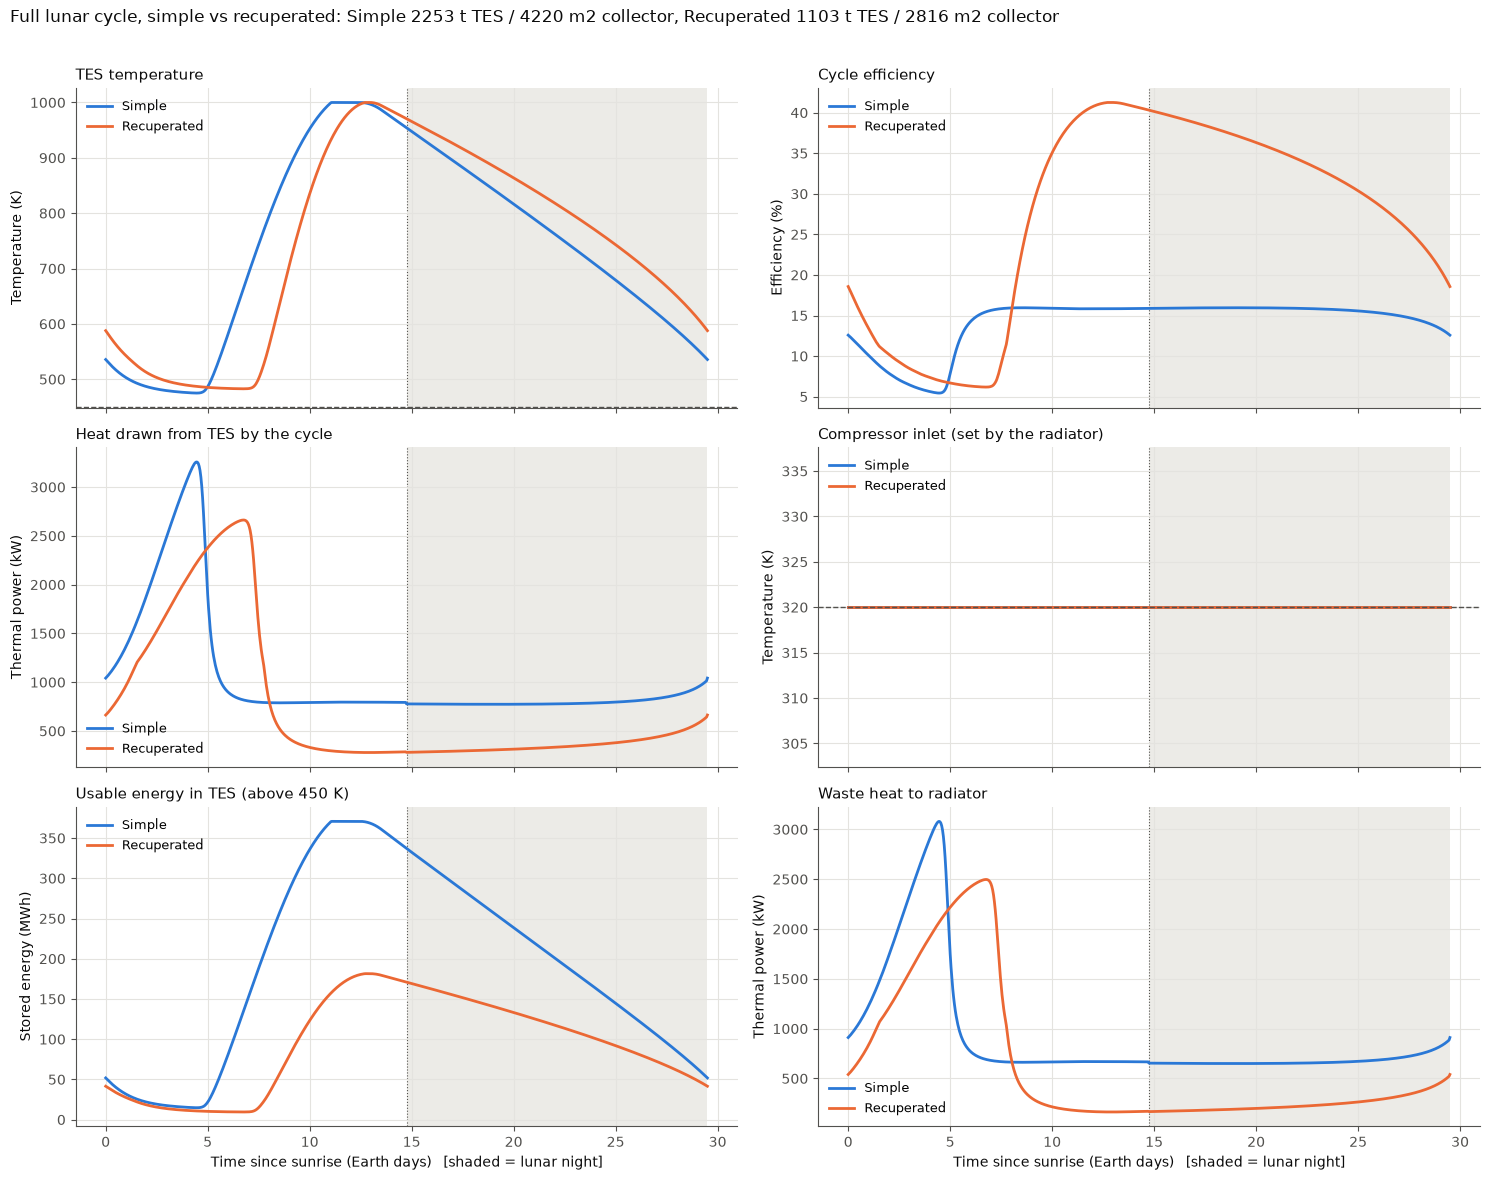

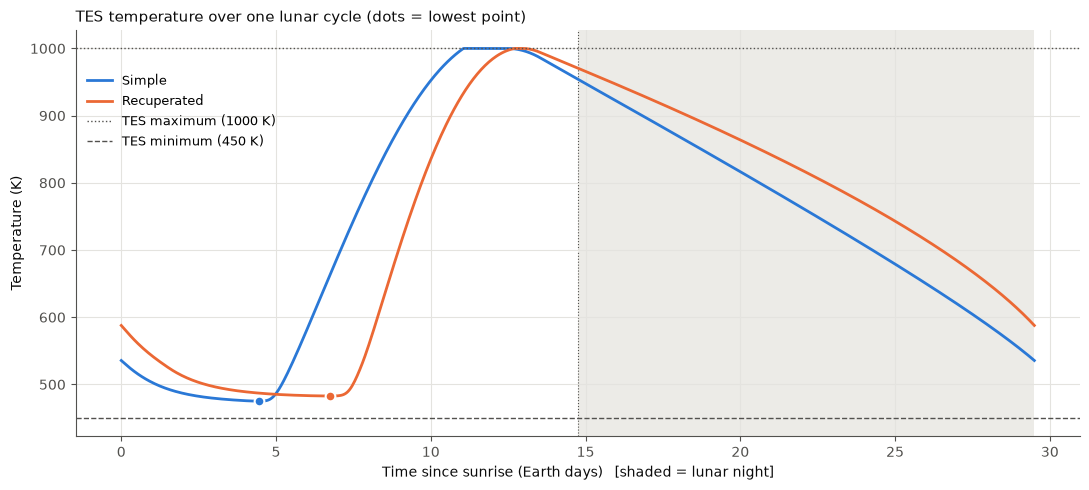

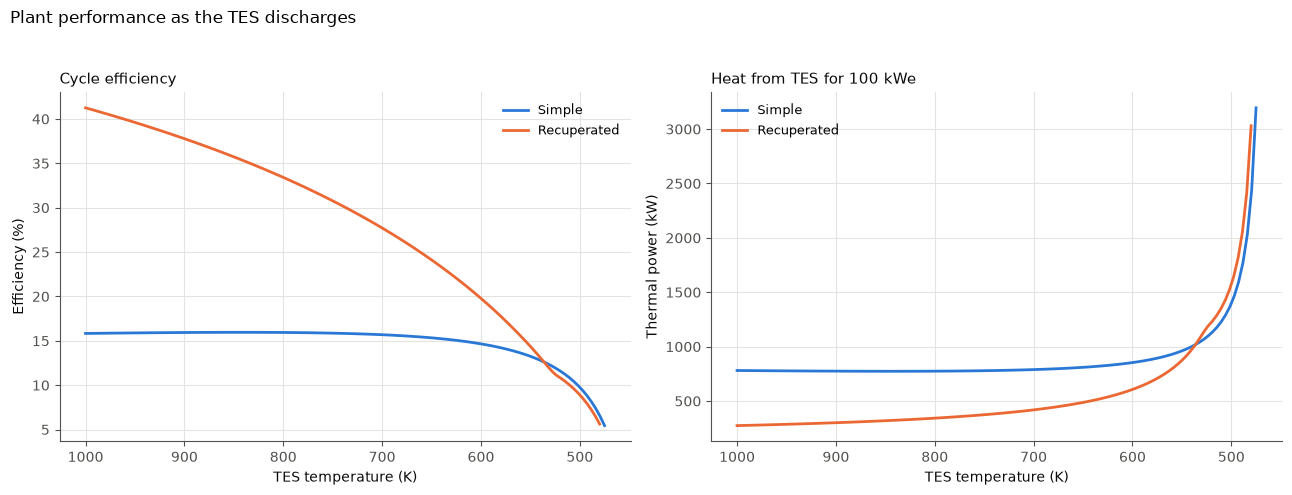

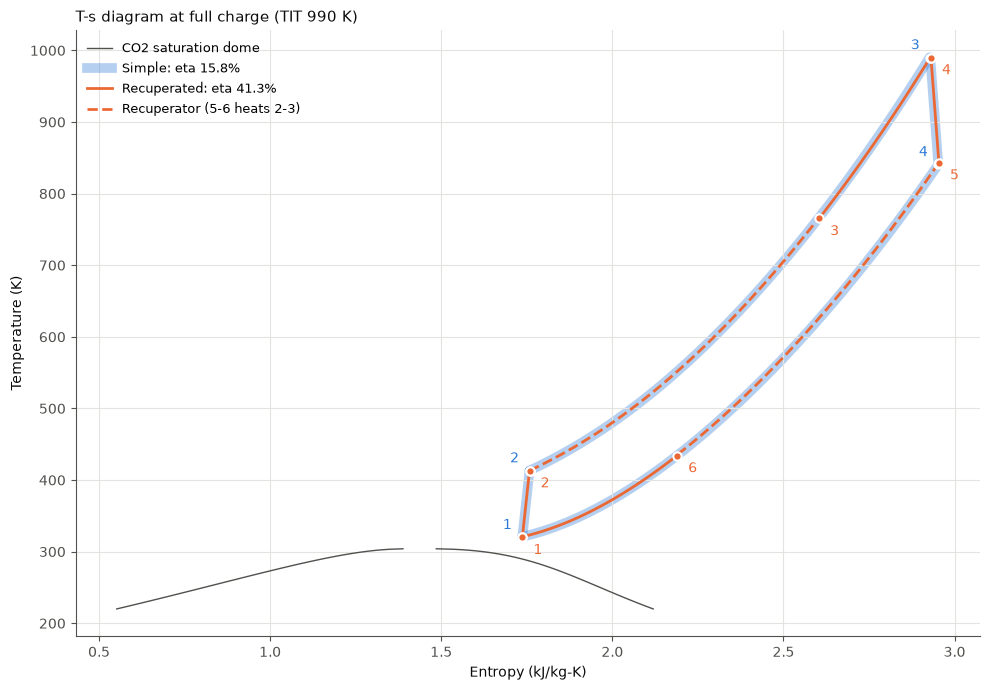

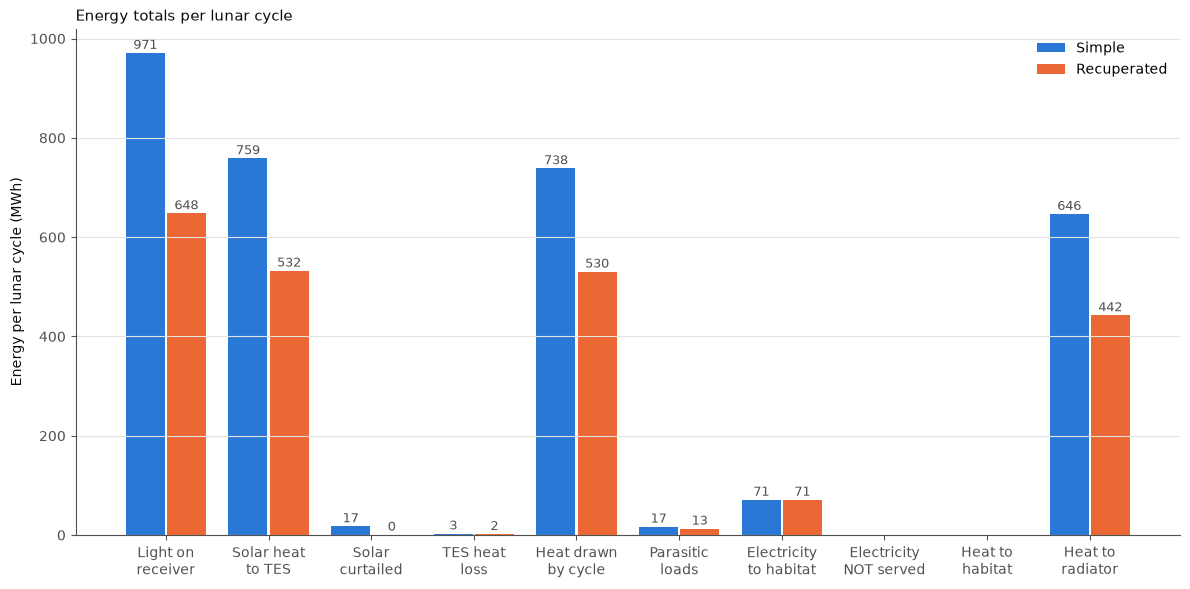

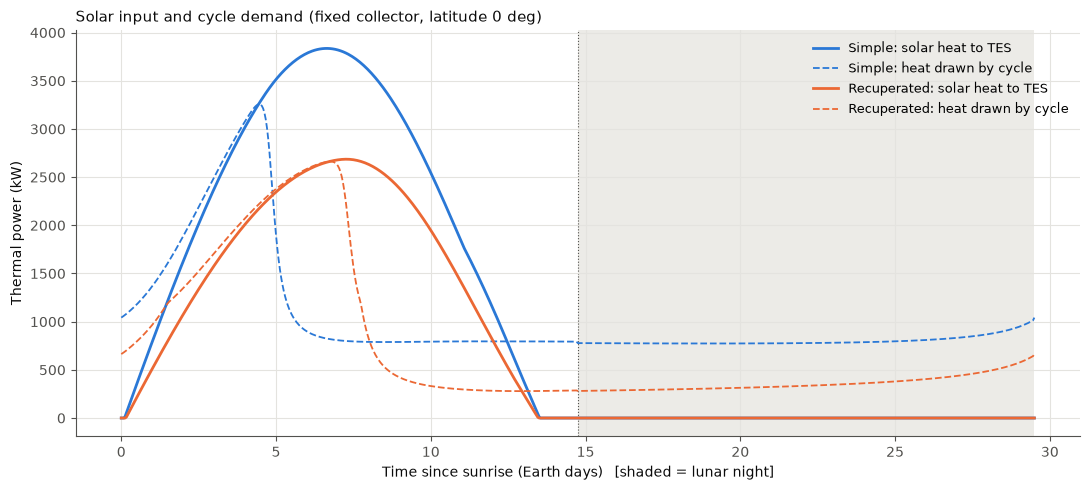

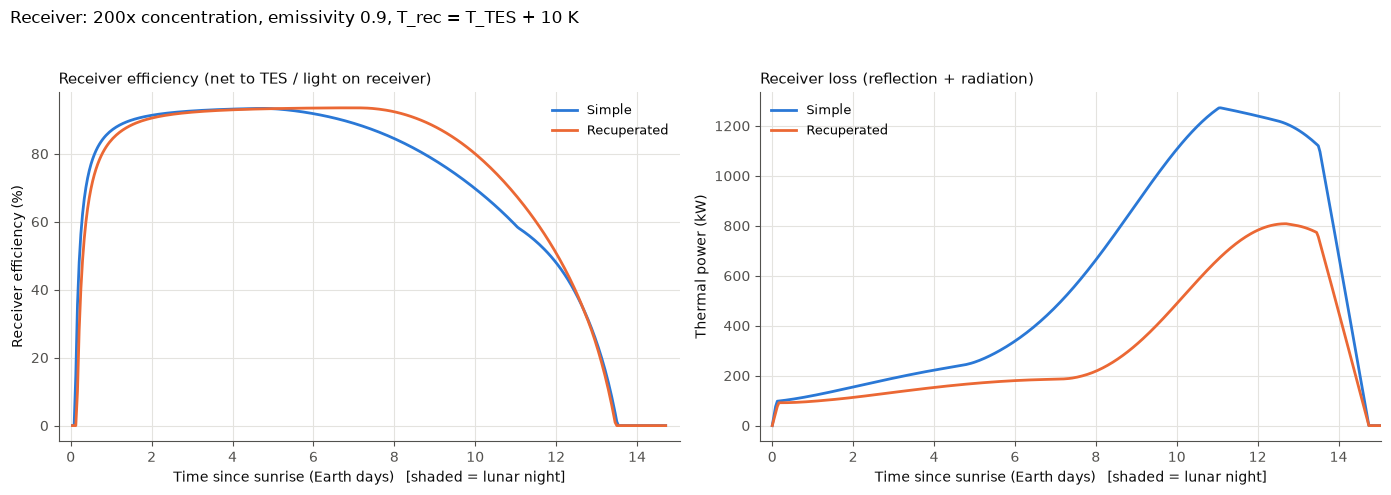

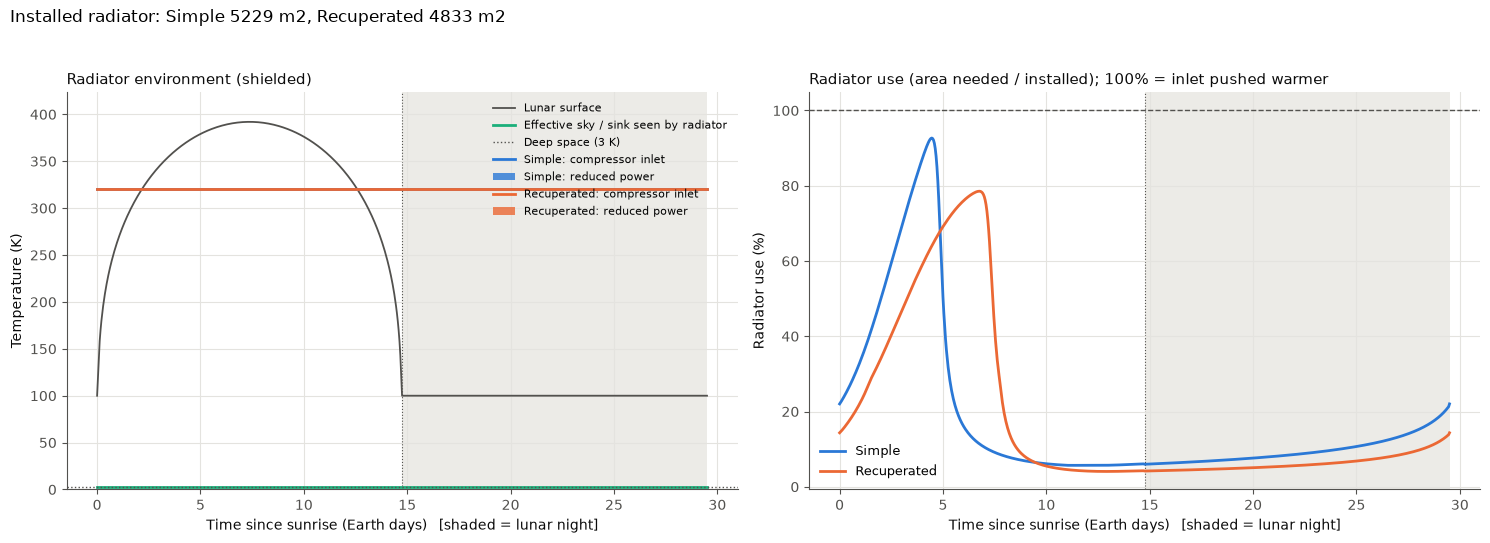

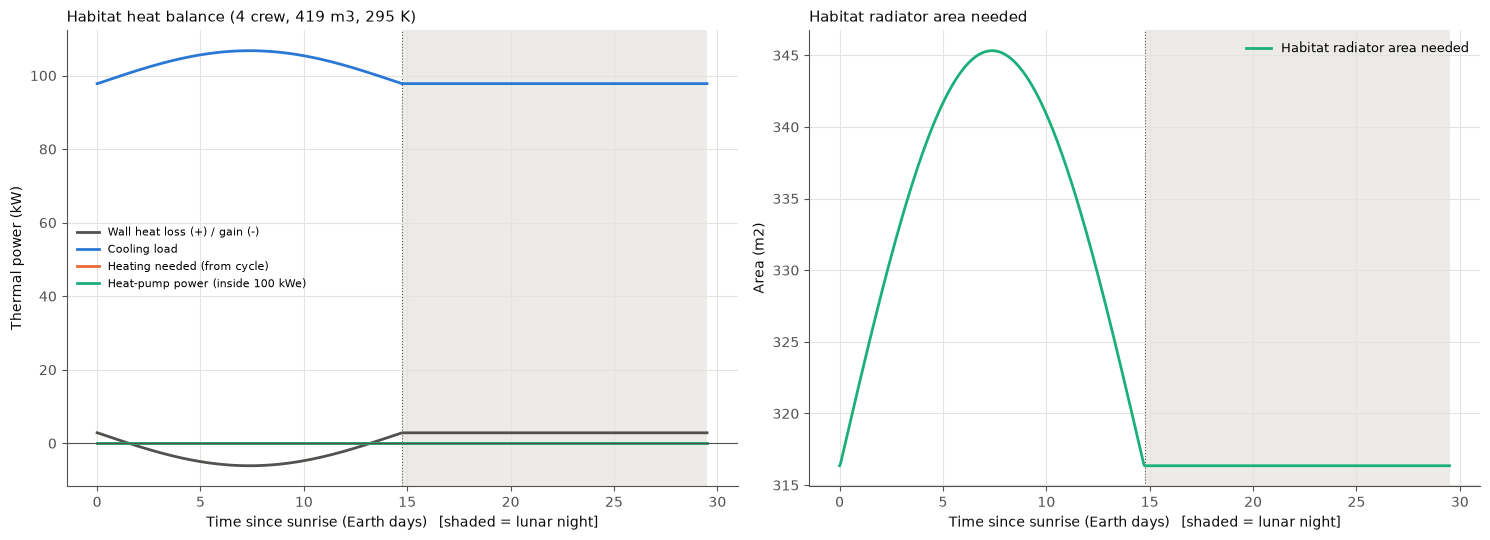

Saved: lunar_power_results.pdf and fig_lunar_cycle.png, fig_TES_temperature.png, fig_vs_TES_temperature.png, fig_Ts_diagram.png, fig_energy_totals.png, fig_solar_input.png, fig_receiver.png, fig_radiator.png, fig_habitat.png


In [13]:
# =====================================================================
# Step 13: Plots, simple vs recuperated (run after Steps 1-12)
# Shows every figure and saves them to one PDF plus individual PNGs
# =====================================================================
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# --- Style: one colour per cycle, used the same way in every figure ---
COL = {'simple': '#2a78d6', 'recuperated': '#eb6834'}
LAB = {'simple': 'Simple', 'recuperated': 'Recuperated'}
C3 = '#1baf7a'
INK, INK2, GRID, NIGHT = '#0b0b0b', '#52514e', '#e4e3df', '#ecebe7'
plt.rcParams.update({
    'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'axes.titlecolor': INK,
    'xtick.color': INK2, 'ytick.color': INK2, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'lines.linewidth': 2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'figure.dpi': 100,
})

days = R[cycles[0]]['cycle']['t'] / 24.0      # time since sunrise, Earth days
sunset_d = t_day / 24.0
XLABEL = 'Time since sunrise (Earth days)   [shaded = lunar night]'

def shade_night(ax):
    ax.axvspan(sunset_d, days[-1], color=NIGHT, zorder=0, lw=0)
    ax.axvline(sunset_d, color=INK2, lw=0.8, ls=':', zorder=1)

def style(ax, ylabel, title, xlabel=None, legend=True, loc='best'):
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc='left')
    if xlabel:
        ax.set_xlabel(xlabel)
    if legend and len(ax.get_lines()) > 1:
        ax.legend(loc=loc, fontsize=9)

def both(ax, key, scale=1.0, **kw):
    for ct in cycles:
        ax.plot(days, R[ct]['cycle'][key] * scale, color=COL[ct], label=LAB[ct], **kw)

figs = []

# ---------------------------------------------------------------------
# Figure 1: one full lunar cycle, both cycles
# ---------------------------------------------------------------------
fig, ax = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
a = ax.ravel()
both(a[0], 'T_TES');                   style(a[0], 'Temperature (K)', 'TES temperature')
a[0].axhline(T_TES_min, color=INK2, lw=1, ls='--')
both(a[1], 'eta', 100);                style(a[1], 'Efficiency (%)', 'Cycle efficiency')
both(a[2], 'Q_in');                    style(a[2], 'Thermal power (kW)', 'Heat drawn from TES by the cycle')
both(a[3], 'T_comp_in');               style(a[3], 'Temperature (K)', 'Compressor inlet (set by the radiator)')
a[3].axhline(T_comp_in, color=INK2, lw=1, ls='--')
both(a[4], 'E_TES', 1e-3);             style(a[4], 'Stored energy (MWh)', f'Usable energy in TES (above {T_TES_min:.0f} K)', XLABEL)
both(a[5], 'Q_rad');                   style(a[5], 'Thermal power (kW)', 'Waste heat to radiator', XLABEL)
for x in a:
    shade_night(x)
fig.suptitle('Full lunar cycle, simple vs recuperated: ' +
             ', '.join(f"{LAB[ct]} {R[ct]['m_TES']/1e3:.0f} t TES / {R[ct]['A_col']:.0f} m2 collector"
                       for ct in cycles),
             x=0.01, ha='left', fontsize=12, color=INK)
fig.tight_layout(rect=[0, 0, 1, 0.97])
figs.append(('lunar_cycle', fig))

# ---------------------------------------------------------------------
# Figure 2: TES temperature over the lunar cycle
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5))
both(ax, 'T_TES')
ax.axhline(T_TES_max, color=INK2, lw=1, ls=':', label=f'TES maximum ({T_TES_max:.0f} K)')
ax.axhline(T_TES_min, color=INK2, lw=1, ls='--', label=f'TES minimum ({T_TES_min:.0f} K)')
for ct in cycles:
    T_ = R[ct]['cycle']['T_TES']; k = np.argmin(T_)
    ax.plot(days[k], T_[k], 'o', color=COL[ct], ms=7, mec='white', mew=1.5)
shade_night(ax)
style(ax, 'Temperature (K)', 'TES temperature over one lunar cycle (dots = lowest point)', XLABEL)
ax.legend(loc='upper left', bbox_to_anchor=(0.0, 0.92), fontsize=9)
fig.tight_layout()
figs.append(('TES_temperature', fig))

# ---------------------------------------------------------------------
# Figure 3: performance versus TES temperature (Section VI.4, night)
# ---------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ct in cycles:
    T_sw = np.linspace(CYC[ct]['T_TES_cutoff'], T_TES_max, 120)
    P_sw = [plant_point(T, ct=ct) for T in T_sw]
    ax[0].plot(T_sw, [p['eta'] * 100 for p in P_sw], color=COL[ct], label=LAB[ct])
    ax[1].plot(T_sw, [p['Q_in'] for p in P_sw], color=COL[ct], label=LAB[ct])
style(ax[0], 'Efficiency (%)', 'Cycle efficiency', 'TES temperature (K)')
style(ax[1], 'Thermal power (kW)', f'Heat from TES for {W_elec_target:.0f} kWe', 'TES temperature (K)')
ax[0].invert_xaxis()       # shared x: invert once; reads left to right as the TES discharges
fig.suptitle('Plant performance as the TES discharges', x=0.01, ha='left', fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.95])
figs.append(('vs_TES_temperature', fig))

# ---------------------------------------------------------------------
# Figure 4: T-s diagram at full charge, both cycles
# ---------------------------------------------------------------------
def s_of(h, P):
    return CP.PropsSI('S', 'H', h, 'P', P, FLUID) / 1e3
def T_of(h, P):
    return CP.PropsSI('T', 'H', h, 'P', P, FLUID)
def isobar(P, ha, hb, n=60):
    h = np.linspace(ha, hb, n)
    return np.array([s_of(x, P) for x in h]), np.array([T_of(x, P) for x in h])

fig, ax = plt.subplots(figsize=(10, 7))
Ts = np.linspace(220, 304.0, 120)
ax.plot([CP.PropsSI('S', 'T', T, 'Q', 0, FLUID) / 1e3 for T in Ts], Ts, color=INK2, lw=1)
ax.plot([CP.PropsSI('S', 'T', T, 'Q', 1, FLUID) / 1e3 for T in Ts], Ts, color=INK2, lw=1,
        label='CO2 saturation dome')
for ct in cycles:
    col = COL[ct]
    if ct == 'simple':
        r = simple_cycle(TIT_max)
        pts = list(zip([r['h1'], r['h2'], r['h3'], r['h4']], r['P']))
        legs = [('line', 0, 1), ('isobar', 1, 2), ('line', 2, 3), ('isobar', 3, 0)]
    else:
        r = recuperated_cycle(TIT_max)
        pts = list(zip([r['h1'], r['h2'], r['h3'], r['h4'], r['h5'], r['h6']], r['P']))
        legs = [('line', 0, 1), ('isobar', 1, 2), ('isobar', 2, 3), ('line', 3, 4),
                ('isobar', 4, 5), ('isobar', 5, 0)]
    # simple: wide translucent band underneath; recuperated: thin line on top,
    # with the two recuperator legs (2-3 cold side, 5-6 hot side) dashed
    lw, alpha, z = (7, 0.35, 1) if ct == 'simple' else (2, 1.0, 3)
    recup_legs = {(1, 2), (4, 5)} if ct == 'recuperated' else set()
    for kind, i, j in legs:
        (hi, Pi), (hj, Pj) = pts[i], pts[j]
        ls = '--' if (i, j) in recup_legs else '-'
        if kind == 'line':
            ax.plot([s_of(hi, Pi), s_of(hj, Pj)], [T_of(hi, Pi), T_of(hj, Pj)],
                    color=col, lw=lw, alpha=alpha, ls=ls, zorder=z, solid_capstyle='round')
        else:
            x, y = isobar(Pi, hi, hj)
            ax.plot(x, y, color=col, lw=lw, alpha=alpha, ls=ls, zorder=z, solid_capstyle='round')
    ax.plot([], [], color=col, lw=lw if ct == 'simple' else 2, alpha=alpha,
            label=f"{LAB[ct]}: eta {r['eta']*100:.1f}%")
    if ct == 'recuperated':
        ax.plot([], [], color=col, ls='--', label='Recuperator (5-6 heats 2-3)')
    for n, (h, P) in enumerate(pts, 1):
        ax.plot(s_of(h, P), T_of(h, P), 'o', color=col, ms=6, mec='white', mew=1.5, zorder=4)
        ax.annotate(str(n), (s_of(h, P), T_of(h, P)), textcoords='offset points',
                    xytext=(8, -12) if ct == 'recuperated' else (-14, 6), color=col, zorder=5)
style(ax, 'Temperature (K)', f'T-s diagram at full charge (TIT {TIT_max:.0f} K)', 'Entropy (kJ/kg-K)',
      legend=False)
ax.legend(loc='upper left', fontsize=9)
fig.tight_layout()
figs.append(('Ts_diagram', fig))

# ---------------------------------------------------------------------
# Figure 5: energy totals per lunar cycle, both cycles
# ---------------------------------------------------------------------
items = [('Q_sun_in', 'Light on\nreceiver'), ('Q_solar', 'Solar heat\nto TES'), ('Q_curtail', 'Solar\ncurtailed'),
         ('Q_loss', 'TES heat\nloss'), ('Q_in', 'Heat drawn\nby cycle'), ('W_aux', 'Parasitic\nloads'),
         ('W_elec', 'Electricity\nto habitat'),
         ('W_unserved', 'Electricity\nNOT served'),
         ('Q_hab', 'Heat to\nhabitat'), ('Q_rad', 'Heat to\nradiator')]
tot = lambda d, k: np.sum(d[k][:-1]) * dt / 1e3
x = np.arange(len(items)); w = 0.38
fig, ax = plt.subplots(figsize=(12, 6))
for i, ct in enumerate(cycles):
    off = (-1 if i == 0 else 1) * (w / 2 + 0.01)
    bars = ax.bar(x + off, [tot(R[ct]['cycle'], k) for k, _ in items], w, color=COL[ct], label=LAB[ct])
    for b in bars:
        if b.get_height() > 0.05:
            ax.annotate(f'{b.get_height():.0f}', (b.get_x() + b.get_width()/2, b.get_height()),
                        textcoords='offset points', xytext=(0, 3), ha='center', fontsize=9, color=INK2)
ax.set_xticks(x, [lbl for _, lbl in items])
ax.grid(axis='x', visible=False)
style(ax, 'Energy per lunar cycle (MWh)', 'Energy totals per lunar cycle', legend=False)
ax.legend()
fig.tight_layout()
figs.append(('energy_totals', fig))

# ---------------------------------------------------------------------
# Figure 6: solar input vs cycle demand
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5))
for ct in cycles:
    ax.plot(days, R[ct]['cycle']['Q_solar'], color=COL[ct], label=f"{LAB[ct]}: solar heat to TES")
    ax.plot(days, R[ct]['cycle']['Q_in'], color=COL[ct], lw=1.3, ls='--', label=f"{LAB[ct]}: heat drawn by cycle")
shade_night(ax)
style(ax, 'Thermal power (kW)', f'Solar input and cycle demand ({collector_mode} collector, '
      f'latitude {latitude_deg:.0f} deg)', XLABEL)
fig.tight_layout()
figs.append(('solar_input', fig))

# ---------------------------------------------------------------------
# Figure 6b: receiver efficiency and loss through the lunar day
# ---------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ct in cycles:
    cy = R[ct]['cycle']
    ax[0].plot(days, cy['eta_rec_t'] * 100, color=COL[ct], label=LAB[ct])
    ax[1].plot(days, cy['Q_rec_loss'], color=COL[ct], label=LAB[ct])
style(ax[0], 'Receiver efficiency (%)', 'Receiver efficiency (net to TES / light on receiver)', XLABEL)
style(ax[1], 'Thermal power (kW)', 'Receiver loss (reflection + radiation)', XLABEL)
ax[0].set_xlim(-0.3, sunset_d + 0.3)
fig.suptitle(f'Receiver: {C_ratio:.0f}x concentration, emissivity {eps_rec}, '
             f'T_rec = T_TES + {dT_rec:.0f} K', x=0.01, ha='left', fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.95])
figs.append(('receiver', fig))

# ---------------------------------------------------------------------
# Figure 7: radiator environment, compressor inlet and radiator use
# ---------------------------------------------------------------------
_cy = R[cycles[0]]['cycle']
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True)
ax[0].plot(days, T_surface(_cy['t']), color=INK2, lw=1.3, label='Lunar surface')
ax[0].plot(days, _cy['T_sink'], color=C3, label='Effective sky / sink seen by radiator')
ax[0].axhline(T_space, color=INK2, lw=1, ls=':', label=f'Deep space ({T_space:.0f} K)')
for k, ct in enumerate(cycles):
    cy = R[ct]['cycle']
    ax[0].plot(days, cy['T_comp_in'], color=COL[ct], label=f'{LAB[ct]}: compressor inlet')
    ax[0].fill_between(days, 0.03 * k, 0.03 * (k + 1), where=cy['part_load'] | ~cy['running'],
                       transform=ax[0].get_xaxis_transform(), color=COL[ct], alpha=0.8, lw=0,
                       label=f'{LAB[ct]}: reduced power')
    ax[1].plot(days, np.where(cy['running'], cy['rad_use'], np.nan) * 100, color=COL[ct], label=LAB[ct])
for x in ax:
    shade_night(x)
style(ax[0], 'Temperature (K)',
      f"Radiator environment ({'shielded' if shield else f'view factor to surface {F_rad_surf}'})",
      XLABEL, legend=False)
ax[0].legend(loc='upper right', fontsize=8)
ax[0].set_ylim(0, max(T_surf_noon, T_comp_in_max) * 1.08)
ax[1].axhline(100, color=INK2, lw=1, ls='--')
style(ax[1], 'Radiator use (%)', 'Radiator use (area needed / installed); 100% = inlet pushed warmer',
      XLABEL)
fig.suptitle('Installed radiator: ' + ', '.join(f"{LAB[ct]} {A_RAD[ct]:.0f} m2" for ct in cycles),
             x=0.01, ha='left', fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.95])
figs.append(('radiator', fig))

# ---------------------------------------------------------------------
# Figure 8: habitat heat balance through the lunar cycle
# ---------------------------------------------------------------------
_hb = R[cycles[0]]['cycle']
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True)
ax[0].plot(days, _hb['Q_hab_wall'], color=INK2, label='Wall heat loss (+) / gain (-)')
ax[0].plot(days, _hb['Q_hab_cool'], color=COL['simple'], label='Cooling load')
ax[0].plot(days, _hb['Q_hab_need'], color=COL['recuperated'], label='Heating needed (from cycle)')
ax[0].plot(days, _hb['W_hp'], color=C3, label='Heat-pump power (inside 100 kWe)')
ax[0].axhline(0, color=INK2, lw=0.8)
ax[1].plot(days, _hb['A_hab_rad'], color=C3, label='Habitat radiator area needed')
for x in ax:
    shade_night(x)
style(ax[0], 'Thermal power (kW)', f'Habitat heat balance ({n_crew} crew, {V_hab:.0f} m3, {T_hab:.0f} K)', XLABEL)
style(ax[1], 'Area (m2)', 'Habitat radiator area needed', XLABEL)
ax[0].legend(fontsize=8)
fig.tight_layout()
figs.append(('habitat', fig))

# --- Save and show ---
with PdfPages('lunar_power_results.pdf') as pdf:
    for name, f in figs:
        pdf.savefig(f)
        f.savefig(f'fig_{name}.png', dpi=150)
plt.show()
print("Saved: lunar_power_results.pdf and", ", ".join(f"fig_{n}.png" for n, _ in figs))